# AWFNO 2D Kolmogorov flow — FULL architectural and sensitivity ablations

**A one-run-per-Colab-session, resumable 22-configuration suite.** Uses the previously corrected AWFNO implementation, **not** the original two-block version. Expects the independently verified **300 × 128 × 128 × 101** vorticity dataset (absolute t=0.25–0.50) and immutable source SHA `7030bc43e6331cdf472182ae0ed4f2684c18da8d336ca9ed92c37baf0bfc8a06`.

**All planned experiments** (duplicates executed just once): 3 ordering permutations LGL/GLL/LLG; GGG Fourier-only and LLL local-only; temporal K=2/5/10/20; Fourier modes M=8/16/24/32; local convolution radius r=1/2/3; depth D=2/4/6; Ntrain=25/50/100/200; and repeat seeds for GLL and LGL. These are *one-factor-at-a-time*, not a 4-D exhaustive grid, totaling 22 distinct runs; all reference settings share K5/M16/D4/r2/N100. Equal-parameter orderings compare architecture directly; component ablations are **not parameter-matched**, so the notebook always reports counts.

**Boussinesq-style figures automatically saved for each completed model:** vorticity `truth / prediction / |error|` at five times for two validation trajectories; training history; absolute and relative error vs time; persistence baseline; top-decile sharp-gradient-region errors; Fourier frequency-band errors. Overall: family-wise ablation comparison and overlaid error-vs-time plots, with summary CSV/JSON.

**Critical experimental design:** The 70 test trajectories are never read into training or validation arrays or used for model selection. Dataset normalization is fitted on training only; validation uses complete free autoregressive rollouts, not teacher forcing. Training windows use every available starting time (stride 1). Checkpoints are saved to Google Drive and completed configurations automatically skipped. Per-session budget is configurable; **one run of the notebook does not guarantee all 22 expensive models complete**. Re-run training cell until `[FULL SUITE COMPLETE]` appears.

**Scientific limitations:** This suite uses one principal random seed, with two additional seeds for the key GLL/LGL comparison; it is not an exhaustive multiple-seed confidence study. Test evaluation should occur only after the validation-based design is frozen.

In [1]:
#@title 1. Verify dataset, mount Google Drive and configure AWFNO pilot
from google.colab import drive
from pathlib import Path
import torch, subprocess, sys, json, hashlib, os, numpy as np, time
drive.mount('/content/drive')
assert torch.cuda.is_available(), 'Use Runtime > Change runtime type > GPU'
print('GPU:',torch.cuda.get_device_name(0))

DATASET=Path('/content/drive/MyDrive/Kolmogorov_NS_Re500_start0.25_horizon0.25_dt0.0025_v1/kolmogorov_dataset.pt')
METADATA=DATASET.parent/'metadata.json'
SOURCE_SHA='82786a4293ac29bf23756c2cc39188e3b7fbb84bd26ef47061415fe76103ebb3'
EXPECTED_SHA='7030bc43e6331cdf472182ae0ed4f2684c18da8d336ca9ed92c37baf0bfc8a06'
assert DATASET.exists() and METADATA.exists(), 'Dataset missing: '+str(DATASET)
meta=json.loads(METADATA.read_text())
assert meta['status']=='PASS' and meta['sha256']==EXPECTED_SHA
assert meta['parent_sha256']==SOURCE_SHA and meta['shape']==[300,128,128,101]
try:
    raw=torch.load(DATASET,map_location='cpu',weights_only=True,mmap=True)
except TypeError:
    raw=torch.load(DATASET,map_location='cpu',weights_only=True)
assert raw['U'].shape==(300,128,128,101)
assert raw['U'].dtype==torch.float32
assert float(raw['forecast_start'])==0.25
assert float(raw['T_forecast'])==0.25
assert abs(float(raw['times'][-1])-.25)<1e-7
assert abs(float(raw['times'][1])-.0025)<1e-7
for name,a,b in [('train_indices',0,200),('val_indices',200,230),('test_indices',230,300)]:
    assert torch.equal(raw[name],torch.arange(a,b))
VERIFY_FILE_HASH=False #@param {type:'boolean'}
if VERIFY_FILE_HASH:
    h=hashlib.sha256()
    with open(DATASET,'rb') as f:
        for buffer in iter(lambda:f.read(8*1024*1024),b''):h.update(buffer)
    assert h.hexdigest()==EXPECTED_SHA, 'The dataset file bytes differ'
print('Data verified from metadata, indices, physical time, shape and provenance.')
if not VERIFY_FILE_HASH:print('[NOTE] Dataset SHA from generation metadata, not independently recomputed here.')
EXPERIMENT='full' #@param ['full']
N_TRAIN=100 #@param {type:'integer'}
K_ORDER=5 #@param {type:'integer'}
ORDER_K='GLL' #@param ['LGL','GLL','LLG']
MAX_UPDATES=1500 #@param {type:'integer'}
BATCH=8 #@param {type:'integer'}
VAL_EVERY=250 #@param {type:'integer'}
MIN_UPDATES=750 #@param {type:'integer'}
PATIENCE=3 #@param {type:'integer'}
MAX_SESSION_MINUTES=180 #@param {type:'integer'}
LAYERS=4 #@param {type:'integer'}
WIDTH=32 #@param {type:'integer'}
MODES=16 #@param {type:'integer'}
RADIUS=2 #@param {type:'integer'}
SEED=1234 #@param {type:'integer'}
assert EXPERIMENT=='full'
assert N_TRAIN<=200 and N_TRAIN>=25
assert MAX_UPDATES>=MIN_UPDATES and MAX_UPDATES>=VAL_EVERY
assert BATCH>=1 and MAX_SESSION_MINUTES>=5
assert K_ORDER in (1,2,4,5,10,20,25,50) and 100%K_ORDER==0
ROOT=Path('/content/drive/MyDrive/AWFNO_NS_Re500_101_FULL_ABLATIONS_v1')
ROOT.mkdir(parents=True,exist_ok=True)
print('FULL ABLATIONS: default N=',N_TRAIN,'| base K=',K_ORDER,'| layers=',LAYERS)
print('Output:',ROOT)


Mounted at /content/drive
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Data verified from metadata, indices, physical time, shape and provenance.
[NOTE] Dataset SHA from generation metadata, not independently recomputed here.
FULL ABLATIONS: default N= 100 | base K= 5 | layers= 4
Output: /content/drive/MyDrive/AWFNO_NS_Re500_101_FULL_ABLATIONS_v1


In [2]:
%%writefile /content/kolmogorov2d_vorticity_benchmark.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Kolmogorov 2D vorticity benchmark for neural-operator surrogates.

The script compares four models:
    1. TB-AWFNO: temporal-basis alternating windowed Fourier neural operator
    2. AWFNO: alternating windowed Fourier neural operator
    3. WFNO: windowed Fourier neural operator baseline
    4. FNO: non-windowed Fourier neural operator baseline

Expected dataset:
    kolmogorov_dataset_parallel/kolmogorov_dataset.pt

Required keys:
    U or omega      : array of shape (N, Nx, Ny, Nt)
    x, y            : spatial grids
    times           : time grid
    train_indices   : training split
    val_indices     : validation split
    test_indices    : test split

Internal layout:
    S has shape (N, Nx, Ny, Nt, 1), where the last channel stores vorticity.

Evaluation protocol:
    - train, validation, and test trajectories are disjoint;
    - the same test set is used for all sample sizes;
    - the temporal basis is computed from training windows only;
    - test trajectories are evaluated without test-window fitting or basis projection;
    - windowed models are initialized only from the true initial condition;
    - subsequent window inputs are previous predictions.

Primary metric:
    absolute physical L2 error.
"""

import os, gc, json, copy, time, random, hashlib
from pathlib import Path
from collections import OrderedDict

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ============================================================
# 0. CONFIG
# ============================================================

SEED = 1234
RAW_DATA_DIR = Path('/content/awfno_reference')
DATA_PATH = RAW_DATA_DIR / "kolmogorov_dataset.pt"
FIELD_KEY = "U"  # "U" or "omega"

# Use 2 for 128x128 -> 64x64. Use 1 for full 128x128.
SPATIAL_STRIDE = 1
TIME_SUBSAMPLE = 1

SAMPLE_SIZES = [25, 50, 100, 200]
N_TRAIN_POOL = max(SAMPLE_SIZES)
N_VAL = 30
N_TEST = 70
SPLIT_SEED = 2026
USE_FILE_SPLITS = True

WINDOW_K = 5
WINDOW_STRIDE = 5
N_TIME_MODES = 4

BATCH_SIZE = 128
EPOCHS = 200
LR = 1e-3
WEIGHT_DECAY = 1e-6

WIDTH = 32
N_LAYERS = 2
MODES_X = 16
MODES_Y = 16
LOCAL_RADIUS = 2

LOSS_KIND = "mse"
HUBER_BETA = 0.02
FINAL_LOSS_WEIGHT = 1.0
GRAD_LOSS_WEIGHT = 0.0
NORMALIZE_LOSS = True
ENFORCE_MEAN = False

FORCE_RETRAIN = False
USE_SPLIT_CACHE = True
SAVE_SPLIT_CACHE = True

RUN_EXACT_HASH_OVERLAP_CHECK = True
RUN_DUPLICATE_REPORT_INSIDE_SPLITS = True
RUN_ROLLOUT_INPUT_GAP_CHECK = True

DEBUG_SHUFFLE_TRAIN_OUTPUTS = False
DEBUG_RANDOM_BASIS = False
INPUT_GAP_TOL = 1e-12

SAVE_PLOTS = True
MAKE_TRAINING_CURVE_PLOTS = True
MAKE_L2_PER_TIME_PLOT = True
MAKE_FIELD_PLOTS = True
PLOT_CHANNEL = 0
PLOT_TIME_INDICES_MANUAL = [5, 10, 25, "final"]
MAX_TEST_CASES_TO_PLOT = 5
PLOT_DPI = 140
L2_CHUNK_SIZE = 8
SAVE_ROLLOUT_ARRAYS = False

X_LEFT, X_RIGHT = 0.0, 1.0
Y_LEFT, Y_RIGHT = 0.0, 1.0
DT_FALLBACK = 0.005

CACHE_ROOT = (
    f"cache_KOLMOGOROV_TB_AWFNO_AWFNO_WFNO_FNO_"
    f"sizes{'-'.join(map(str, SAMPLE_SIZES))}_"
    f"K{WINDOW_K}_M{N_TIME_MODES}_W{WIDTH}_"
    f"mx{MODES_X}_my{MODES_Y}_R{LOCAL_RADIUS}_"
    f"xstride{SPATIAL_STRIDE}_tsub{TIME_SUBSAMPLE}"
)
for suffix, flag in [("_SHUFFLED", DEBUG_SHUFFLE_TRAIN_OUTPUTS), ("_RANDOMBASIS", DEBUG_RANDOM_BASIS)]:
    if flag:
        CACHE_ROOT += suffix

MODEL_DIR = os.path.join(CACHE_ROOT, "models")
PLOT_DIR = os.path.join(CACHE_ROOT, "plots")
DATA_DIR = os.path.join(CACHE_ROOT, "data")
RESULTS_DIR = os.path.join(CACHE_ROOT, "results")
for d in [MODEL_DIR, PLOT_DIR, DATA_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ============================================================
# 1. DEVICE / GLOBAL GEOMETRY
# ============================================================

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

x_grid_np = y_grid_np = t_grid = None
Nx = Ny = Nt = C_DYN = None
DX = DY = DT_SNAPSHOT = None

def set_geometry(S_shape, x=None, y=None, t=None):
    global x_grid_np, y_grid_np, t_grid, Nx, Ny, Nt, C_DYN, DX, DY, DT_SNAPSHOT
    _, Nx, Ny, Nt, C_DYN = S_shape
    if x is None:
        x_grid_np = np.linspace(X_LEFT, X_RIGHT, Nx, endpoint=False, dtype=np.float32)
    else:
        x_grid_np = np.asarray(x, dtype=np.float32).reshape(-1)[:Nx]
    if y is None:
        y_grid_np = np.linspace(Y_LEFT, Y_RIGHT, Ny, endpoint=False, dtype=np.float32)
    else:
        y_grid_np = np.asarray(y, dtype=np.float32).reshape(-1)[:Ny]
    DX = float(np.mean(np.diff(x_grid_np.astype(np.float64)))) if Nx > 1 else 1.0
    DY = float(np.mean(np.diff(y_grid_np.astype(np.float64)))) if Ny > 1 else 1.0
    if t is None or len(t) != Nt:
        t_grid = np.arange(Nt, dtype=np.float32) * DT_FALLBACK
        DT_SNAPSHOT = float(DT_FALLBACK)
    else:
        t_grid = np.asarray(t, dtype=np.float32).reshape(-1)
        DT_SNAPSHOT = float(np.mean(np.diff(t_grid.astype(np.float64)))) if Nt > 1 else float(DT_FALLBACK)
    print("\nGeometry")
    print("--------")
    print("Nx, Ny, Nt, C:", Nx, Ny, Nt, C_DYN)
    print("DX, DY, DT   :", DX, DY, DT_SNAPSHOT)

# ============================================================
# 2. HELPERS
# ============================================================

def short_hash(obj):
    return hashlib.md5(json.dumps(obj, sort_keys=True).encode()).hexdigest()[:10]

def clean_state_dict(sd):
    sd = copy.deepcopy(sd)
    if isinstance(sd, dict) and "_metadata" in sd:
        del sd["_metadata"]
    if hasattr(sd, "_metadata"):
        try: del sd._metadata
        except Exception: pass
    return OrderedDict((k, v) for k, v in sd.items() if k != "_metadata")

def save_model_checkpoint(path, model, meta=None):
    torch.save({"state_dict": clean_state_dict(model.state_dict()), "meta": meta or {}}, path)

def load_model_checkpoint(path, model):
    payload = torch.load(path, map_location=device)
    model.load_state_dict(clean_state_dict(payload["state_dict"]), strict=True)
    return payload.get("meta", {})

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def gb(nbytes): return nbytes / 1024**3

def print_array_info(name, arr):
    print(f"{name:18s}: shape={arr.shape}, dtype={arr.dtype}, memory={gb(arr.nbytes):.3f} GB, "
          f"min={float(np.nanmin(arr)):+.4e}, max={float(np.nanmax(arr)):+.4e}, "
          f"mean={float(np.nanmean(arr)):+.4e}, std={float(np.nanstd(arr)):.4e}")

def time_weights(nt):
    w = np.ones(nt, dtype=np.float64)
    if nt > 1:
        w[0] = 0.5
        w[-1] = 0.5
    return w

# ============================================================
# 3. HDF5 LOADER
# ============================================================


def safe_torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def split_cache_path():
    return os.path.join(DATA_DIR, "split_" + short_hash({
        "path": str(DATA_PATH),
        "field": FIELD_KEY,
        "stride": SPATIAL_STRIDE,
        "tsub": TIME_SUBSAMPLE,
        "sizes": SAMPLE_SIZES,
        "use_file_splits": USE_FILE_SPLITS,
        "seed": SPLIT_SEED,
    }) + ".npz")


def make_random_split_indices(n_total):
    need = N_TRAIN_POOL + N_VAL + N_TEST
    if need > n_total:
        raise ValueError(f"Need {need} trajectories but file has only {n_total}.")
    rng = np.random.default_rng(SPLIT_SEED)
    perm = rng.permutation(n_total)
    train_idx = perm[:N_TRAIN_POOL]
    val_idx = perm[N_TRAIN_POOL:N_TRAIN_POOL+N_VAL]
    test_idx = perm[N_TRAIN_POOL+N_VAL:N_TRAIN_POOL+N_VAL+N_TEST]
    return train_idx, val_idx, test_idx


def load_split_cache():
    path = split_cache_path()
    if not USE_SPLIT_CACHE or not os.path.exists(path):
        return None
    print("\nLoading split cache:", path)
    z = np.load(path, allow_pickle=True)
    return (z["S_train_pool"].astype(np.float32), z["S_val"].astype(np.float32), z["S_test"].astype(np.float32),
            z["train_idx"], z["val_idx"], z["test_idx"],
            z["x_grid"].astype(np.float32), z["y_grid"].astype(np.float32), z["t_grid"].astype(np.float32))


def save_split_cache(S_train_pool, S_val, S_test, train_idx, val_idx, test_idx, x, y, t):
    if not SAVE_SPLIT_CACHE:
        return
    path = split_cache_path()
    np.savez(path, S_train_pool=S_train_pool, S_val=S_val, S_test=S_test,
             train_idx=train_idx, val_idx=val_idx, test_idx=test_idx,
             x_grid=x.astype(np.float32), y_grid=y.astype(np.float32), t_grid=t.astype(np.float32))
    print("Saved split cache:", path)


def load_or_create_split():
    cached = load_split_cache()
    if cached is not None:
        return cached
    if not DATA_PATH.exists():
        raise FileNotFoundError(DATA_PATH)

    data = safe_torch_load(DATA_PATH)

    print("\nKeys in .pt file")
    print("----------------")
    for k in data.keys():
        print(" ", k)

    if FIELD_KEY not in data:
        raise KeyError(f"FIELD_KEY={FIELD_KEY!r} not found. Available keys: {list(data.keys())}")

    U = data[FIELD_KEY]
    U = U.float().cpu().numpy() if torch.is_tensor(U) else np.asarray(U, dtype=np.float32)

    if U.ndim != 4:
        raise ValueError(f"Expected {FIELD_KEY} with shape (N,Nx,Ny,Nt). Got {U.shape}")

    x = data["x"]
    y = data["y"]
    t = data["times"]
    x = x.float().cpu().numpy() if torch.is_tensor(x) else np.asarray(x, dtype=np.float32)
    y = y.float().cpu().numpy() if torch.is_tensor(y) else np.asarray(y, dtype=np.float32)
    t = t.float().cpu().numpy() if torch.is_tensor(t) else np.asarray(t, dtype=np.float32)

    U = U[:, ::SPATIAL_STRIDE, ::SPATIAL_STRIDE, ::TIME_SUBSAMPLE].astype(np.float32, copy=False)
    x = x[::SPATIAL_STRIDE].astype(np.float32)
    y = y[::SPATIAL_STRIDE].astype(np.float32)
    t = t[::TIME_SUBSAMPLE].astype(np.float32)

    S = U[..., None].astype(np.float32, copy=False)  # (N,Nx,Ny,Nt,1)

    if USE_FILE_SPLITS:
        required = ["train_indices", "val_indices", "test_indices"]
        missing = [k for k in required if k not in data]
        if missing:
            raise KeyError(f"USE_FILE_SPLITS=True, but missing split keys: {missing}")

        train_idx = data["train_indices"]
        val_idx = data["val_indices"]
        test_idx = data["test_indices"]

        train_idx = train_idx.long().cpu().numpy() if torch.is_tensor(train_idx) else np.asarray(train_idx, dtype=np.int64)
        val_idx = val_idx.long().cpu().numpy() if torch.is_tensor(val_idx) else np.asarray(val_idx, dtype=np.int64)
        test_idx = test_idx.long().cpu().numpy() if torch.is_tensor(test_idx) else np.asarray(test_idx, dtype=np.int64)

        if max(SAMPLE_SIZES) > len(train_idx):
            raise ValueError(f"max(SAMPLE_SIZES)={max(SAMPLE_SIZES)} but train split has only {len(train_idx)} samples.")

        S_train_pool = S[train_idx]
        S_val = S[val_idx]
        S_test = S[test_idx]

    else:
        train_idx, val_idx, test_idx = make_random_split_indices(S.shape[0])
        S_train_pool = S[train_idx]
        S_val = S[val_idx]
        S_test = S[test_idx]

    print("\nLoaded Kolmogorov data")
    print("----------------------")
    print("FIELD_KEY:", FIELD_KEY)
    print("S shape  :", S.shape, "= (N,Nx,Ny,Nt,1)")
    print("x shape  :", x.shape)
    print("y shape  :", y.shape)
    print("t shape  :", t.shape)

    for key in ["Re", "nu", "forcing_mode", "dt", "T_spinup", "T_forecast", "axis_order"]:
        if key in data:
            val = data[key]
            if torch.is_tensor(val):
                val = val.item() if val.numel() == 1 else val.cpu().tolist()
            print(f"{key}: {val}")

    print("\nSplit")
    print("-----")
    print("S_train_pool:", S_train_pool.shape)
    print("S_val       :", S_val.shape)
    print("S_test      :", S_test.shape)
    print("train_idx first/last:", train_idx[:5], train_idx[-5:])
    print("val_idx   first/last:", val_idx[:5], val_idx[-5:])
    print("test_idx  first/last:", test_idx[:5], test_idx[-5:])

    save_split_cache(S_train_pool, S_val, S_test, train_idx, val_idx, test_idx, x, y, t)
    return S_train_pool, S_val, S_test, train_idx, val_idx, test_idx, x, y, t

# ============================================================
# 4. CHECKS / METRICS
# ============================================================

def trajectory_hashes(S):
    S32 = np.ascontiguousarray(S.astype(np.float32, copy=False))
    return [hashlib.sha1(S32[i].tobytes()).hexdigest() for i in range(S32.shape[0])]

def check_exact_overlap(A, B, name_a, name_b):
    inter = set(trajectory_hashes(A)).intersection(set(trajectory_hashes(B)))
    print(f"\nExact overlap check {name_a} vs {name_b}: duplicates={len(inter)}")
    if inter:
        raise RuntimeError(f"Duplicate trajectories found between {name_a} and {name_b}.")

def report_duplicates(S, name):
    h = trajectory_hashes(S)
    seen, dup = {}, []
    for i, x in enumerate(h):
        if x in seen: dup.append((seen[x], i))
        else: seen[x] = i
    print(f"\nDuplicate check inside {name}: total={len(h)}, unique={len(seen)}, duplicates={len(dup)}")
    if dup: print("first duplicate pairs:", dup[:10])
    return dup

def abs_l2_window_batch(pred, true):
    return torch.sqrt(torch.sum((pred - true)**2, dim=(1,2,3,4))*DX*DY*DT_SNAPSHOT + 1e-30)

def abs_l2_field_batch(pred, true):
    return torch.sqrt(torch.sum((pred - true)**2, dim=(1,2,3))*DX*DY + 1e-30)

def l2_per_timestep_np(pred, true):
    n, nx, ny, nt, c = pred.shape
    out = np.zeros((n, nt), dtype=np.float64)
    for i0 in range(0, n, L2_CHUNK_SIZE):
        i1 = min(i0 + L2_CHUNK_SIZE, n)
        err = pred[i0:i1].astype(np.float32) - true[i0:i1].astype(np.float32)
        out[i0:i1] = np.sqrt(np.sum(err*err, axis=(1,2,4), dtype=np.float64)*DX*DY + 1e-30)
    return out

def rollout_l2_metrics(pred, true):
    l2_t = l2_per_timestep_np(pred, true)
    w = time_weights(l2_t.shape[1]).reshape(1,-1)
    full = np.sqrt(np.sum(w*l2_t**2, axis=1)*DT_SNAPSHOT + 1e-30)
    final = l2_t[:, -1]
    return {
        "full_l2_mean": float(np.mean(full)), "full_l2_std": float(np.std(full)), "full_l2_median": float(np.median(full)),
        "final_l2_mean": float(np.mean(final)), "final_l2_std": float(np.std(final)), "final_l2_median": float(np.median(final)),
        "mean_t": np.mean(l2_t, axis=0), "median_t": np.median(l2_t, axis=0), "std_t": np.std(l2_t, axis=0),
        "all_full_l2": full, "all_final_l2": final, "all_l2_t": l2_t,
    }

# ============================================================
# 5. DATASETS / BASIS / NORMALIZER
# ============================================================

def make_window_start_indices(nt, K, stride):
    if nt <= K:
        raise ValueError(f"Need Nt > K. Got Nt={nt}, K={K}")
    return list(range(0, nt-K, stride))

class WindowDataset(Dataset):
    def __init__(self, S, starts, shuffle_targets=False):
        self.S = S.astype(np.float32, copy=False)
        self.starts = list(starts)
        self.n = self.S.shape[0]
        self.ns = len(self.starts)
        self.shuffle_targets = shuffle_targets
        self.target_perm = np.random.default_rng(SEED).permutation(self.n*self.ns) if shuffle_targets else None
    def __len__(self): return self.n*self.ns
    def decode(self, idx):
        i = idx // self.ns
        s = self.starts[idx % self.ns]
        return i, s
    def __getitem__(self, idx):
        i, s = self.decode(idx)
        if self.target_perm is None:
            it, st = i, s
        else:
            it, st = self.decode(int(self.target_perm[idx]))
        return {
            "state_start": torch.tensor(self.S[i,:,:,s,:], dtype=torch.float32),
            "state_future": torch.tensor(self.S[it,:,:,st+1:st+WINDOW_K+1,:], dtype=torch.float32),
        }

class FullDataset(Dataset):
    def __init__(self, S):
        self.S = S.astype(np.float32, copy=False)
    def __len__(self): return self.S.shape[0]
    def __getitem__(self, idx):
        return {
            "state0": torch.tensor(self.S[idx,:,:,0,:], dtype=torch.float32),
            "future": torch.tensor(self.S[idx,:,:,1:,:], dtype=torch.float32),
            "full": torch.tensor(self.S[idx], dtype=torch.float32),
        }

def compute_tb_basis(S, starts, n_modes):
    K = WINDOW_K
    cov = np.zeros((K,K), dtype=np.float64)
    rows = 0
    for i in range(S.shape[0]):
        for s in starts:
            S0 = S[i,:,:,s,:]
            Sf = S[i,:,:,s+1:s+K+1,:]
            R = Sf - S0[:,:,None,:]
            X = np.transpose(R, (0,1,3,2)).reshape(-1,K).astype(np.float64)
            cov += X.T @ X
            rows += X.shape[0]
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    eigvals, eigvecs = eigvals[order], eigvecs[:,order]
    r = min(n_modes, K)
    basis = eigvecs[:,:r].astype(np.float32)
    energy = np.maximum(eigvals, 0)
    ratio = float(np.sum(energy[:r])/(np.sum(energy)+1e-30))
    print("\nTemporal basis")
    print("--------------")
    print("rows:", rows, "rank:", r, "energy:", f"{ratio:.10f}", "singular:", np.sqrt(energy)[:10])
    return basis, ratio, np.sqrt(energy).astype(np.float32)

def random_basis(K, M):
    Q, _ = np.linalg.qr(np.random.randn(K, M))
    return Q[:, :M].astype(np.float32)

def reconstruct_tb(state_start, coeff, basis, enforce_mean=False):
    R = torch.einsum("bxycm,km->bxykc", coeff, basis)
    Sf = state_start.unsqueeze(3) + R
    if enforce_mean:
        m0 = state_start.mean(dim=(1,2), keepdim=True).unsqueeze(3)
        Sf = Sf + m0 - Sf.mean(dim=(1,2), keepdim=True)
    return Sf

def enforce_mean_future(Sf, state_start):
    m0 = state_start.mean(dim=(1,2), keepdim=True).unsqueeze(3)
    return Sf + m0 - Sf.mean(dim=(1,2), keepdim=True)

class ChannelNormalizer:
    def __init__(self, mean, std, eps=1e-6):
        self.mean = torch.tensor(mean, dtype=torch.float32)
        self.std = torch.tensor(np.maximum(std, 1e-8), dtype=torch.float32)
        self.eps = eps
    def _view(self, x):
        if x.dim() == 4:
            return self.mean.view(1,1,1,-1), self.std.view(1,1,1,-1)
        if x.dim() == 5:
            return self.mean.view(1,1,1,1,-1), self.std.view(1,1,1,1,-1)
        raise ValueError(x.shape)
    def encode(self, x):
        m, s = self._view(x); return (x-m)/(s+self.eps)
    def decode(self, x):
        m, s = self._view(x); return x*(s+self.eps)+m
    def to(self, device):
        self.mean = self.mean.to(device); self.std = self.std.to(device); return self

def channel_stats(S):
    mean = np.mean(S, axis=(0,1,2,3), dtype=np.float64).astype(np.float32)
    std = np.std(S, axis=(0,1,2,3), dtype=np.float64).astype(np.float32)
    return mean, std

# ============================================================
# 6. MODELS
# ============================================================

class SpectralConv2d(nn.Module):
    def __init__(self, in_ch, out_ch, modes_x, modes_y):
        super().__init__()
        scale = 1.0/np.sqrt(in_ch*out_ch)
        self.modes_x = modes_x; self.modes_y = modes_y
        self.weights_pos = nn.Parameter(scale*torch.randn(in_ch, out_ch, modes_x, modes_y, dtype=torch.cfloat))
        self.weights_neg = nn.Parameter(scale*torch.randn(in_ch, out_ch, modes_x, modes_y, dtype=torch.cfloat))
    @staticmethod
    def cmul(a, b): return torch.einsum("bixy,ioxy->boxy", a, b)
    def forward(self, x):
        B,C,nx,ny = x.shape
        x_ft = torch.fft.rfft2(x, norm="ortho")
        out_ft = torch.zeros(B, self.weights_pos.shape[1], nx, ny//2+1, dtype=torch.cfloat, device=x.device)
        mx = min(self.modes_x, nx); my = min(self.modes_y, ny//2+1)
        out_ft[:,:,:mx,:my] = self.cmul(x_ft[:,:,:mx,:my], self.weights_pos[:,:,:mx,:my])
        out_ft[:,:,-mx:,:my] = self.cmul(x_ft[:,:,-mx:,:my], self.weights_neg[:,:,:mx,:my])
        return torch.fft.irfft2(out_ft, s=(nx,ny), norm="ortho")

class ExactLKLBlock(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.L1 = nn.Conv2d(width, width, 2*LOCAL_RADIUS+1, padding=LOCAL_RADIUS, padding_mode="circular")
        self.K = SpectralConv2d(width, width, MODES_X, MODES_Y)
        self.L2 = nn.Conv2d(width, width, 2*LOCAL_RADIUS+1, padding=LOCAL_RADIUS, padding_mode="circular")
        self.sigma = nn.GELU()
    def forward(self, v):
        v1 = v + self.sigma(self.L1(v))
        v2 = v1 + self.sigma(self.K(v1))
        return v2 + self.sigma(self.L2(v2))

class GridMixin:
    def make_grid(self):
        x = torch.tensor(x_grid_np, dtype=torch.float32)
        y = torch.tensor(y_grid_np, dtype=torch.float32)
        xn = (x-x.min())/(x.max()-x.min()+1e-12)
        yn = (y-y.min())/(y.max()-y.min()+1e-12)
        X,Y = torch.meshgrid(xn, yn, indexing="ij")
        return torch.stack([X,Y,torch.sin(2*np.pi*X),torch.cos(2*np.pi*X),torch.sin(2*np.pi*Y),torch.cos(2*np.pi*Y)], dim=-1)

class AWEncoder(nn.Module, GridMixin):
    def __init__(self, c_in):
        super().__init__()
        self.register_buffer("grid", self.make_grid().unsqueeze(0), persistent=False)
        self.input_proj = nn.Linear(c_in+6, WIDTH)
        self.blocks = nn.ModuleList([ExactLKLBlock(WIDTH) for _ in range(N_LAYERS)])
    def forward(self, s_norm):
        B = s_norm.shape[0]
        z = torch.cat([s_norm, self.grid.repeat(B,1,1,1)], dim=-1)
        z = self.input_proj(z).permute(0,3,1,2).contiguous()
        for b in self.blocks: z = b(z)
        return z.permute(0,2,3,1).contiguous()

class FNOEncoder(nn.Module, GridMixin):
    def __init__(self, c_in):
        super().__init__()
        self.register_buffer("grid", self.make_grid().unsqueeze(0), persistent=False)
        self.fc0 = nn.Linear(c_in+6, WIDTH)
        self.convs = nn.ModuleList([SpectralConv2d(WIDTH, WIDTH, MODES_X, MODES_Y) for _ in range(N_LAYERS)])
        self.ws = nn.ModuleList([nn.Conv2d(WIDTH, WIDTH, 1) for _ in range(N_LAYERS)])
    def forward(self, s_norm):
        B = s_norm.shape[0]
        z = torch.cat([s_norm, self.grid.repeat(B,1,1,1)], dim=-1)
        z = self.fc0(z).permute(0,3,1,2).contiguous()
        for i,(conv,w) in enumerate(zip(self.convs, self.ws)):
            z = conv(z) + w(z)
            if i != len(self.convs)-1: z = F.gelu(z)
        return z.permute(0,2,3,1).contiguous()

class TBAWFNO(nn.Module):
    def __init__(self, c_dyn, m):
        super().__init__()
        self.c_dyn = c_dyn; self.m = m
        self.encoder = AWEncoder(c_dyn)
        self.fc1 = nn.Linear(WIDTH, 128)
        self.fc2 = nn.Linear(128, c_dyn*m)
    def forward(self, s_norm):
        z = self.encoder(s_norm)
        out = self.fc2(F.gelu(self.fc1(z)))
        B,nx,ny,_ = out.shape
        return out.view(B,nx,ny,self.c_dyn,self.m)

class DirectWindowModel(nn.Module):
    def __init__(self, c_dyn, K, encoder_kind):
        super().__init__()
        self.c_dyn = c_dyn; self.K = K
        self.encoder = AWEncoder(c_dyn) if encoder_kind == "AW" else FNOEncoder(c_dyn)
        self.fc1 = nn.Linear(WIDTH, 128)
        self.fc2 = nn.Linear(128, c_dyn*K)
    def forward(self, s_norm):
        z = self.encoder(s_norm)
        out = self.fc2(F.gelu(self.fc1(z)))
        B,nx,ny,_ = out.shape
        return out.view(B,nx,ny,self.K,self.c_dyn)

class FNOFull(nn.Module):
    def __init__(self, c_dyn, nt_future):
        super().__init__()
        self.c_dyn = c_dyn; self.nt_future = nt_future
        self.encoder = FNOEncoder(c_dyn)
        self.fc1 = nn.Linear(WIDTH, 128)
        self.fc2 = nn.Linear(128, c_dyn*nt_future)
    def forward(self, s0_norm):
        z = self.encoder(s0_norm)
        out = self.fc2(F.gelu(self.fc1(z)))
        B,nx,ny,_ = out.shape
        return out.view(B,nx,ny,self.nt_future,self.c_dyn)

def make_tb_predict(model, normer, basis):
    def predict(s):
        coeff = model(normer.encode(s))
        return coeff, reconstruct_tb(s, coeff, basis, ENFORCE_MEAN)
    return predict

def make_direct_predict(model, normer, out_normer, enforce_mean=False):
    def predict(s):
        out = out_normer.decode(model(normer.encode(s)))
        return enforce_mean_future(out, s) if enforce_mean else out
    return predict

def make_full_predict(model, normer, out_normer):
    def predict(s0):
        return out_normer.decode(model(normer.encode(s0)))
    return predict

# ============================================================
# 7. LOSSES / FIT
# ============================================================

def data_loss(pred, true):
    if LOSS_KIND == "mse": return F.mse_loss(pred, true)
    if LOSS_KIND == "huber": return F.smooth_l1_loss(pred, true, beta=HUBER_BETA)
    raise ValueError(LOSS_KIND)

def norm_loss(pred, true, normer):
    return data_loss(normer.encode(pred), normer.encode(true)) if NORMALIZE_LOSS else data_loss(pred, true)

def grad_loss(pred, true, normer):
    p = normer.encode(pred) if NORMALIZE_LOSS else pred
    t = normer.encode(true) if NORMALIZE_LOSS else true
    px = (torch.roll(p,-1,1)-torch.roll(p,1,1))/(2*DX)
    py = (torch.roll(p,-1,2)-torch.roll(p,1,2))/(2*DY)
    tx = (torch.roll(t,-1,1)-torch.roll(t,1,1))/(2*DX)
    ty = (torch.roll(t,-1,2)-torch.roll(t,1,2))/(2*DY)
    return F.smooth_l1_loss(px,tx,beta=HUBER_BETA) + F.smooth_l1_loss(py,ty,beta=HUBER_BETA)

def window_loss(pred, true, normer):
    return (norm_loss(pred, true, normer)
            + FINAL_LOSS_WEIGHT*norm_loss(pred[:,:,:,-1,:], true[:,:,:,-1,:], normer)
            + GRAD_LOSS_WEIGHT*grad_loss(pred, true, normer))

def train_epoch_windowed(model, loader, opt, predict, normer, kind):
    model.train(); tot=tot_l2=n=0
    for batch in loader:
        s0 = batch["state_start"].to(device); true = batch["state_future"].to(device)
        opt.zero_grad(set_to_none=True)
        pred = predict(s0)[1] if kind == "TB-AWFNO" else predict(s0)
        loss = window_loss(pred, true, normer)
        loss.backward()
        if kind in ["TB-AWFNO", "AWFNO"]: torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        bs=s0.shape[0]; tot += loss.item()*bs; tot_l2 += abs_l2_window_batch(pred.detach(), true).mean().item()*bs; n += bs
    return {"loss": tot/max(n,1), "abs_l2": tot_l2/max(n,1)}

@torch.no_grad()
def eval_epoch_windowed(model, loader, predict, normer, kind):
    model.eval(); tot=tot_l2=tot_final=n=0
    for batch in loader:
        s0 = batch["state_start"].to(device); true = batch["state_future"].to(device)
        pred = predict(s0)[1] if kind == "TB-AWFNO" else predict(s0)
        loss = window_loss(pred, true, normer)
        bs=s0.shape[0]; tot += loss.item()*bs; tot_l2 += abs_l2_window_batch(pred, true).mean().item()*bs
        tot_final += abs_l2_field_batch(pred[:,:,:,-1,:], true[:,:,:,-1,:]).mean().item()*bs; n += bs
    return {"loss": tot/max(n,1), "abs_l2": tot_l2/max(n,1), "final_l2": tot_final/max(n,1)}

def fit_windowed(model, train_loader, val_loader, predict, normer, kind):
    if kind in ["TB-AWFNO", "AWFNO"]:
        opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(EPOCHS//3,1), gamma=0.5)
    best=float("inf"); best_state=None
    hist={"train_loss":[],"train_l2":[],"val_loss":[],"val_l2":[],"val_final_l2":[]}
    t0=time.time()
    for ep in range(1,EPOCHS+1):
        tr = train_epoch_windowed(model, train_loader, opt, predict, normer, kind)
        va = eval_epoch_windowed(model, val_loader, predict, normer, kind)
        sched.step()
        for k,v in [("train_loss",tr["loss"]),("train_l2",tr["abs_l2"]),("val_loss",va["loss"]),("val_l2",va["abs_l2"]),("val_final_l2",va["final_l2"])]:
            hist[k].append(v)
        if va["abs_l2"] < best:
            best = va["abs_l2"]; best_state = clean_state_dict(model.state_dict())
        if ep == 1 or ep % 10 == 0:
            print(f"[{kind}] {ep:04d}/{EPOCHS} | train loss {tr['loss']:.6e} | train L2 {tr['abs_l2']:.6e} | val loss {va['loss']:.6e} | val L2 {va['abs_l2']:.6e} | val final {va['final_l2']:.6e}")
    if best_state is not None: model.load_state_dict(best_state, strict=True)
    return {"model": model, "best_val_l2": best, "train_time_sec": time.time()-t0, "history": hist}

def train_epoch_full(model, loader, opt, predict, normer):
    model.train(); tot=tot_l2=n=0
    for batch in loader:
        s0=batch["state0"].to(device); true=batch["future"].to(device)
        opt.zero_grad(set_to_none=True)
        pred=predict(s0)
        loss = window_loss(pred, true, normer)
        loss.backward(); opt.step()
        bs=s0.shape[0]; tot += loss.item()*bs; tot_l2 += abs_l2_window_batch(pred.detach(), true).mean().item()*bs; n += bs
    return {"loss": tot/max(n,1), "abs_l2": tot_l2/max(n,1)}

@torch.no_grad()
def eval_epoch_full(model, loader, predict, normer):
    model.eval(); tot=tot_l2=tot_final=n=0
    for batch in loader:
        s0=batch["state0"].to(device); true=batch["future"].to(device)
        pred=predict(s0)
        loss=window_loss(pred, true, normer)
        bs=s0.shape[0]; tot += loss.item()*bs; tot_l2 += abs_l2_window_batch(pred, true).mean().item()*bs
        tot_final += abs_l2_field_batch(pred[:,:,:,-1,:], true[:,:,:,-1,:]).mean().item()*bs; n += bs
    return {"loss": tot/max(n,1), "abs_l2": tot_l2/max(n,1), "final_l2": tot_final/max(n,1)}

def fit_full(model, train_loader, val_loader, predict, normer):
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(EPOCHS//3,1), gamma=0.5)
    best=float("inf"); best_state=None
    hist={"train_loss":[],"train_l2":[],"val_loss":[],"val_l2":[],"val_final_l2":[]}
    t0=time.time()
    for ep in range(1,EPOCHS+1):
        tr=train_epoch_full(model, train_loader, opt, predict, normer)
        va=eval_epoch_full(model, val_loader, predict, normer)
        sched.step()
        for k,v in [("train_loss",tr["loss"]),("train_l2",tr["abs_l2"]),("val_loss",va["loss"]),("val_l2",va["abs_l2"]),("val_final_l2",va["final_l2"])]:
            hist[k].append(v)
        if va["abs_l2"] < best:
            best=va["abs_l2"]; best_state=clean_state_dict(model.state_dict())
        if ep == 1 or ep % 10 == 0:
            print(f"[FNO] {ep:04d}/{EPOCHS} | train loss {tr['loss']:.6e} | train L2 {tr['abs_l2']:.6e} | val loss {va['loss']:.6e} | val L2 {va['abs_l2']:.6e} | val final {va['final_l2']:.6e}")
    if best_state is not None: model.load_state_dict(best_state, strict=True)
    return {"model": model, "best_val_l2": best, "train_time_sec": time.time()-t0, "history": hist}

# ============================================================
# 8. ROLLOUT / EVALUATION
# ============================================================

def check_input_gap(current, S_batch, cursor, name):
    if not RUN_ROLLOUT_INPUT_GAP_CHECK or cursor <= 0: return
    true = torch.tensor(S_batch[:,:,:,cursor,:], dtype=torch.float32, device=device)
    gap = abs_l2_field_batch(current, true).mean().item()
    print(f"  CHECK {name}: input gap from true at cursor {cursor}: {gap:.6e}")
    if gap < INPUT_GAP_TOL:
        raise RuntimeError(f"Possible cheating in {name}: input equals true state at cursor {cursor}")

@torch.no_grad()
def rollout_tb(model, S_test, predict):
    model.eval(); n,nx,ny,nt,c = S_test.shape
    out = np.zeros_like(S_test, dtype=np.float32)
    print("\nSequential rollout: TB-AWFNO")
    for i0 in range(0,n,BATCH_SIZE):
        i1=min(i0+BATCH_SIZE,n); batch=S_test[i0:i1]
        cur=torch.tensor(batch[:,:,:,0,:], dtype=torch.float32, device=device)
        out[i0:i1,:,:,0,:]=batch[:,:,:,0,:]
        cursor=0; blk=0
        while cursor < nt-1:
            check_input_gap(cur,batch,cursor,"TB-AWFNO")
            _, pred = predict(cur)
            use_k = min(WINDOW_K, nt-1-cursor)
            out[i0:i1,:,:,cursor+1:cursor+1+use_k,:] = pred[:,:,:,:use_k,:].detach().cpu().numpy()
            cur = pred[:,:,:,use_k-1,:].detach()
            cursor += use_k; blk += 1
        print(f"  TB-AWFNO predicted {i0:04d}:{i1:04d}")
    return out

@torch.no_grad()
def rollout_direct(model, S_test, predict, name):
    model.eval(); n,nx,ny,nt,c = S_test.shape
    out = np.zeros_like(S_test, dtype=np.float32)
    print(f"\nSequential rollout: {name}")
    for i0 in range(0,n,BATCH_SIZE):
        i1=min(i0+BATCH_SIZE,n); batch=S_test[i0:i1]
        cur=torch.tensor(batch[:,:,:,0,:], dtype=torch.float32, device=device)
        out[i0:i1,:,:,0,:]=batch[:,:,:,0,:]
        cursor=0
        while cursor < nt-1:
            check_input_gap(cur,batch,cursor,name)
            pred = predict(cur)
            use_k = min(WINDOW_K, nt-1-cursor)
            out[i0:i1,:,:,cursor+1:cursor+1+use_k,:] = pred[:,:,:,:use_k,:].detach().cpu().numpy()
            cur = pred[:,:,:,use_k-1,:].detach()
            cursor += use_k
        print(f"  {name} predicted {i0:04d}:{i1:04d}")
    return out

@torch.no_grad()
def predict_full(model, S_test, predict):
    model.eval(); n,nx,ny,nt,c = S_test.shape
    out = np.zeros_like(S_test, dtype=np.float32)
    out[:,:,:,0,:] = S_test[:,:,:,0,:]
    print("\nFull prediction: FNO")
    for i0 in range(0,n,BATCH_SIZE):
        i1=min(i0+BATCH_SIZE,n)
        s0=torch.tensor(S_test[i0:i1,:,:,0,:], dtype=torch.float32, device=device)
        future = predict(s0)
        out[i0:i1,:,:,1:,:] = future.detach().cpu().numpy()
        print(f"  FNO predicted {i0:04d}:{i1:04d}")
    return out

def persistence(S):
    out = np.zeros_like(S, dtype=np.float32)
    out[:] = S[:,:,:,0:1,:]
    return out

def plot_training_curves(hist, name, tag):
    if not SAVE_PLOTS or not MAKE_TRAINING_CURVE_PLOTS: return
    plt.figure(figsize=(8,5))
    plt.semilogy(hist["train_loss"], label="train")
    plt.semilogy(hist["val_loss"], label="val")
    plt.grid(True, alpha=0.3); plt.legend(); plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(f"{name} loss")
    plt.tight_layout(); p=os.path.join(PLOT_DIR, f"{tag}_{name}_loss.png"); plt.savefig(p, dpi=PLOT_DPI); plt.close(); print("Saved:", p)
    plt.figure(figsize=(8,5))
    plt.semilogy(hist["train_l2"], label="train L2")
    plt.semilogy(hist["val_l2"], label="val L2")
    plt.semilogy(hist["val_final_l2"], label="val final L2")
    plt.grid(True, alpha=0.3); plt.legend(); plt.xlabel("epoch"); plt.ylabel("absolute L2"); plt.title(f"{name} L2")
    plt.tight_layout(); p=os.path.join(PLOT_DIR, f"{tag}_{name}_l2.png"); plt.savefig(p, dpi=PLOT_DPI); plt.close(); print("Saved:", p)

def plot_l2_per_time(stats, tag):
    if not SAVE_PLOTS or not MAKE_L2_PER_TIME_PLOT: return
    plt.figure(figsize=(8,5))
    for name, st in stats.items():
        plt.plot(t_grid, st["mean_t"], label=name)
    plt.grid(True, alpha=0.3); plt.legend(); plt.xlabel("time"); plt.ylabel("absolute vorticity L2")
    plt.title("2D Kolmogorov L2 per time")
    plt.tight_layout(); p=os.path.join(PLOT_DIR, f"{tag}_l2_per_time.png"); plt.savefig(p, dpi=PLOT_DPI); plt.close(); print("Saved:", p)

def plot_fields(S_true, rollouts, tag):
    if not SAVE_PLOTS or not MAKE_FIELD_PLOTS: return
    out_dir=os.path.join(PLOT_DIR, f"{tag}_fields_ch{PLOT_CHANNEL}"); os.makedirs(out_dir, exist_ok=True)
    times=[]
    for item in PLOT_TIME_INDICES_MANUAL:
        k = S_true.shape[-2]-1 if item == "final" else int(item)
        if 0 <= k < S_true.shape[-2] and k not in times: times.append(k)
    ch = min(PLOT_CHANNEL, S_true.shape[-1]-1)
    names = list(rollouts.keys())
    for i in range(min(MAX_TEST_CASES_TO_PLOT, S_true.shape[0])):
        for k in times:
            true = S_true[i,:,:,k,ch]
            fields=[true] + [rollouts[n][i,:,:,k,ch] for n in names]
            errs=[np.abs(rollouts[n][i,:,:,k,ch]-true) for n in names]
            vmin=min(float(a.min()) for a in fields); vmax=max(float(a.max()) for a in fields); emax=max(float(e.max()) for e in errs)+1e-12
            fig, axes = plt.subplots(1, 1+2*len(names), figsize=(3*(1+2*len(names)),3.2), constrained_layout=True)
            axes=np.asarray(axes).ravel(); col=0
            im=axes[col].imshow(true.T, origin="lower", vmin=vmin, vmax=vmax); axes[col].set_title("true"); axes[col].axis("off"); col+=1
            for n in names:
                axes[col].imshow(rollouts[n][i,:,:,k,ch].T, origin="lower", vmin=vmin, vmax=vmax); axes[col].set_title(n); axes[col].axis("off"); col+=1
            imerr=None
            for n in names:
                imerr=axes[col].imshow(np.abs(rollouts[n][i,:,:,k,ch]-true).T, origin="lower", vmin=0, vmax=emax); axes[col].set_title(n+" err"); axes[col].axis("off"); col+=1
            fig.colorbar(im, ax=axes[:1+len(names)].tolist(), shrink=0.7)
            fig.colorbar(imerr, ax=axes[1+len(names):].tolist(), shrink=0.7)
            fig.suptitle(f"test {i}, channel {ch}, t index {k}")
            p=os.path.join(out_dir, f"test_{i:03d}_t{k:04d}.png"); plt.savefig(p, dpi=PLOT_DPI); plt.close(fig); print("Saved:", p)

# ============================================================
# 9. TRAIN/EVAL SWEEP
# ============================================================

def base_tag(n_train):
    return short_hash({"N": n_train, "Nx": Nx, "Ny": Ny, "Nt": Nt, "C": C_DYN, "K": WINDOW_K,
                       "M": N_TIME_MODES, "W": WIDTH, "L": N_LAYERS, "mx": MODES_X, "my": MODES_Y,
                       "stride": SPATIAL_STRIDE, "tsub": TIME_SUBSAMPLE})

def build_objects(n_train, S_train_pool, S_val):
    S_train = S_train_pool[:n_train]
    starts = make_window_start_indices(Nt, WINDOW_K, WINDOW_STRIDE)
    val_starts = make_window_start_indices(Nt, WINDOW_K, WINDOW_K)
    print("\nWindow starts:", starts[:10], "n=", len(starts), "val n=", len(val_starts))
    basis, energy, sing = compute_tb_basis(S_train, starts, N_TIME_MODES)
    if DEBUG_RANDOM_BASIS:
        basis = random_basis(WINDOW_K, N_TIME_MODES); energy=float("nan"); sing=np.ones(N_TIME_MODES, dtype=np.float32)
    basis_t = torch.tensor(basis, dtype=torch.float32, device=device)
    mean, std = channel_stats(S_train)
    normer = ChannelNormalizer(mean, std).to(device)
    for c in range(C_DYN): print(f"normalizer ch {c}: mean {mean[c]:+.6e}, std {std[c]:.6e}")
    train_ds = WindowDataset(S_train, starts, DEBUG_SHUFFLE_TRAIN_OUTPUTS)
    val_ds = WindowDataset(S_val, val_starts, False)
    train_full_ds = FullDataset(S_train)
    val_full_ds = FullDataset(S_val)
    gen=torch.Generator(); gen.manual_seed(SEED+n_train)
    train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,generator=gen,num_workers=0,pin_memory=torch.cuda.is_available())
    val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=torch.cuda.is_available())
    train_full_loader=DataLoader(train_full_ds,batch_size=BATCH_SIZE,shuffle=True,generator=gen,num_workers=0,pin_memory=torch.cuda.is_available())
    val_full_loader=DataLoader(val_full_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=torch.cuda.is_available())
    b=next(iter(train_loader)); bf=next(iter(train_full_loader))
    print("batch window:", tuple(b["state_start"].shape), tuple(b["state_future"].shape))
    print("batch full  :", tuple(bf["state0"].shape), tuple(bf["future"].shape))
    return {"S_train": S_train, "basis": basis, "basis_t": basis_t, "energy": energy,
            "train_loader": train_loader, "val_loader": val_loader,
            "train_full_loader": train_full_loader, "val_full_loader": val_full_loader, "normer": normer}

def train_models(n_train, S_train_pool, S_val):
    tag = base_tag(n_train)
    print("\n"+"="*80); print(f"TRAINING N_train={n_train} | tag={tag}"); print("="*80)
    obj = build_objects(n_train, S_train_pool, S_val)
    normer = obj["normer"]
    tb = TBAWFNO(C_DYN, N_TIME_MODES).to(device)
    aw = DirectWindowModel(C_DYN, WINDOW_K, "AW").to(device)
    wf = DirectWindowModel(C_DYN, WINDOW_K, "FNO").to(device)
    fno = FNOFull(C_DYN, Nt-1).to(device)
    preds = {
        "TB-AWFNO": make_tb_predict(tb, normer, obj["basis_t"]),
        "AWFNO": make_direct_predict(aw, normer, normer, ENFORCE_MEAN),
        "WFNO": make_direct_predict(wf, normer, normer, False),
        "FNO": make_full_predict(fno, normer, normer),
    }
    models = {"TB-AWFNO": tb, "AWFNO": aw, "WFNO": wf, "FNO": fno}
    print("\nParameter counts")
    for n,m in models.items(): print(f"{n:8s}: {count_params(m):,}")
    fits={}; paths={}
    for name in ["TB-AWFNO", "AWFNO", "WFNO"]:
        path=os.path.join(MODEL_DIR, f"N{n_train}_{name}_{tag}.pt"); paths[name]=path
        if os.path.exists(path) and not FORCE_RETRAIN:
            print("Loading cached", name, path); meta=load_model_checkpoint(path, models[name])
            fits[name]={"model": models[name], "best_val_l2": meta.get("best_val_l2", float("nan")),
                        "train_time_sec": meta.get("train_time_sec", 0.0), "history": meta.get("history")}
        else:
            fits[name]=fit_windowed(models[name], obj["train_loader"], obj["val_loader"], preds[name], normer, name)
            save_model_checkpoint(path, fits[name]["model"], {k:v for k,v in fits[name].items() if k!="model"})
        if fits[name]["history"] is not None: plot_training_curves(fits[name]["history"], f"N{n_train}_{name}", tag)
    name="FNO"; path=os.path.join(MODEL_DIR, f"N{n_train}_{name}_{tag}.pt"); paths[name]=path
    if os.path.exists(path) and not FORCE_RETRAIN:
        print("Loading cached FNO", path); meta=load_model_checkpoint(path, models[name])
        fits[name]={"model": models[name], "best_val_l2": meta.get("best_val_l2", float("nan")),
                    "train_time_sec": meta.get("train_time_sec", 0.0), "history": meta.get("history")}
    else:
        fits[name]=fit_full(models[name], obj["train_full_loader"], obj["val_full_loader"], preds[name], normer)
        save_model_checkpoint(path, fits[name]["model"], {k:v for k,v in fits[name].items() if k!="model"})
    if fits[name]["history"] is not None: plot_training_curves(fits[name]["history"], f"N{n_train}_{name}", tag)
    return {"n_train": n_train, "tag": tag, "objects": obj, "models": models, "predict": preds, "fits": fits, "paths": paths}

def evaluate(bundle, S_test, test_idx):
    tag=bundle["tag"]; n_train=bundle["n_train"]
    print("\n"+"="*80); print(f"EVALUATION N_train={n_train} on common test set"); print("="*80)
    R={}
    R["TB-AWFNO"] = rollout_tb(bundle["fits"]["TB-AWFNO"]["model"], S_test, bundle["predict"]["TB-AWFNO"])
    R["AWFNO"] = rollout_direct(bundle["fits"]["AWFNO"]["model"], S_test, bundle["predict"]["AWFNO"], "AWFNO")
    R["WFNO"] = rollout_direct(bundle["fits"]["WFNO"]["model"], S_test, bundle["predict"]["WFNO"], "WFNO")
    R["FNO"] = predict_full(bundle["fits"]["FNO"]["model"], S_test, bundle["predict"]["FNO"])
    R["Persistence"] = persistence(S_test)
    stats={name: rollout_l2_metrics(arr, S_test) for name, arr in R.items()}
    print("\n================ ABSOLUTE PHYSICAL VORTICITY L2 TEST RESULTS ================")
    for name in ["TB-AWFNO","AWFNO","WFNO","FNO","Persistence"]:
        st=stats[name]
        tt="" if name=="Persistence" else f" | train time {bundle['fits'][name]['train_time_sec']:.2f}s"
        print(f"{name:12s} | L2(full) mean {st['full_l2_mean']:.6e} | std {st['full_l2_std']:.6e} | median {st['full_l2_median']:.6e} | L2(final) mean {st['final_l2_mean']:.6e}{tt}")
    winner=min(stats, key=lambda k: stats[k]["full_l2_mean"])
    print("Winner:", winner)
    plot_l2_per_time(stats, tag)
    plot_fields(S_test, R, tag)
    if SAVE_ROLLOUT_ARRAYS:
        np.savez_compressed(os.path.join(RESULTS_DIR, f"N{n_train}_rollouts_{tag}.npz"), S_true=S_test, **{k.replace("-","_"):v for k,v in R.items()})
    row={"N_train": n_train, "winner": winner, "pod_energy_ratio_train_only": float(bundle["objects"]["energy"]), "base_tag": tag}
    for name in ["TB-AWFNO","AWFNO","WFNO","FNO","Persistence"]:
        key=name.replace("-","_")
        row[f"{key}_full_l2_mean"]=stats[name]["full_l2_mean"]
        row[f"{key}_final_l2_mean"]=stats[name]["final_l2_mean"]
        if name != "Persistence":
            row[f"{key}_best_val_l2"]=float(bundle["fits"][name]["best_val_l2"])
            row[f"{key}_train_time_sec"]=float(bundle["fits"][name]["train_time_sec"])
    with open(os.path.join(RESULTS_DIR, f"N{n_train}_summary_{tag}.json"), "w") as f:
        json.dump({"row": row, "grid": {"Nx": Nx, "Ny": Ny, "Nt": Nt, "C": C_DYN}}, f, indent=2)
    del R
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return row

def save_results(rows):
    rows=sorted(rows, key=lambda r: r["N_train"])
    keys=list(rows[0].keys())
    csv=os.path.join(RESULTS_DIR, "sample_size_sweep_kolmogorov_absolute_L2.csv")
    with open(csv, "w") as f:
        f.write(",".join(keys)+"\n")
        for r in rows: f.write(",".join(str(r[k]) for k in keys)+"\n")
    js=os.path.join(RESULTS_DIR, "sample_size_sweep_kolmogorov_absolute_L2.json")
    with open(js, "w") as f: json.dump(rows, f, indent=2)
    print("Saved:", csv); print("Saved:", js)
    print("\n================ SAMPLE-SIZE SWEEP SUMMARY: ABSOLUTE FULL L2 ================")
    for r in rows:
        print(f"N={r['N_train']:4d} | TB-AWFNO {r['TB_AWFNO_full_l2_mean']:.6e} | AWFNO {r['AWFNO_full_l2_mean']:.6e} | WFNO {r['WFNO_full_l2_mean']:.6e} | FNO {r['FNO_full_l2_mean']:.6e} | Persistence {r['Persistence_full_l2_mean']:.6e} | winner {r['winner']}")
    print("============================================================================")

# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":
    print("\nProtocol")
    print("--------")
    print("Dataset:", DATA_PATH)
    print("Models: TB-AWFNO, AWFNO, WFNO, FNO, Persistence")
    print("SPATIAL_STRIDE:", SPATIAL_STRIDE, "| TIME_SUBSAMPLE:", TIME_SUBSAMPLE)
    print("Absolute physical vorticity L2 only; no relative denominator.")

    S_train_pool, S_val, S_test, train_idx, val_idx, test_idx, x, y, t = load_or_create_split()
    set_geometry(S_train_pool.shape, x, y, t)

    print("\nLoaded split arrays")
    print_array_info("S_train_pool", S_train_pool)
    print_array_info("S_val", S_val)
    print_array_info("S_test", S_test)

    for c in range(S_train_pool.shape[-1]):
        mid=min(5,S_train_pool.shape[-2]-1)
        print(f"ch {c}: t0 {S_train_pool[0,:,:,0,c].min():+.3e}/{S_train_pool[0,:,:,0,c].max():+.3e} | "
              f"t{mid} {S_train_pool[0,:,:,mid,c].min():+.3e}/{S_train_pool[0,:,:,mid,c].max():+.3e} | "
              f"final {S_train_pool[0,:,:,-1,c].min():+.3e}/{S_train_pool[0,:,:,-1,c].max():+.3e}")

    if not np.all(np.isfinite(S_train_pool)) or not np.all(np.isfinite(S_val)) or not np.all(np.isfinite(S_test)):
        raise ValueError("NaN/Inf found in loaded arrays.")

    if RUN_EXACT_HASH_OVERLAP_CHECK:
        check_exact_overlap(S_train_pool, S_val, "train_pool", "validation")
        check_exact_overlap(S_train_pool, S_test, "train_pool", "common_test")
        check_exact_overlap(S_val, S_test, "validation", "common_test")

    if RUN_DUPLICATE_REPORT_INSIDE_SPLITS:
        report_duplicates(S_train_pool, "train_pool")
        report_duplicates(S_val, "validation")
        report_duplicates(S_test, "common_test")

    bundles=[]
    for n_train in SAMPLE_SIZES:
        bundles.append(train_models(n_train, S_train_pool, S_val))
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    rows=[]
    for b in bundles:
        rows.append(evaluate(b, S_test, test_idx))
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    save_results(rows)
    print("\nDone.")


Writing /content/kolmogorov2d_vorticity_benchmark.py


In [3]:
%%writefile /content/navier_stokes_awfno_ablations.py
#!/usr/bin/env python3
"""FULL AWFNO controlled ablation suite; select using validation rollouts only.

Full validation-only ablation suite on fixed verified data. Does not access the sealed
70 test trajectories or alter the dataset. Includes controlled architecture-order,
component, temporal-window, mode, local radius, depth, sample-size and seed studies.
Uses corrected periodic features and equally weighted temporal targets.

The original baseline's K=5, depth=2 numbers are therefore not directly comparable.
Run with --benchmark /path/to/kolmogorov2d_vorticity_benchmark.py
"""
import argparse
import copy
import csv
import hashlib
import importlib.util
import json
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader


def snapshot(model):
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}


def atomic_json(path,ob):
    temp=path.with_suffix('.json.tmp')
    temp.write_text(json.dumps(ob,indent=2,allow_nan=False))
    temp.replace(path)


def safe_torch_load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False,mmap=True)
    except (RuntimeError,TypeError):return torch.load(path,map_location='cpu',weights_only=False)


def periodic_grid(bm):
    def make_grid(self):
        x=torch.tensor(bm.x_grid_np,dtype=torch.float32)
        y=torch.tensor(bm.y_grid_np,dtype=torch.float32)
        Lx=float(x[1]-x[0])*len(x)
        Ly=float(y[1]-y[0])*len(y)
        xx,yy=torch.meshgrid(2*math.pi*(x-x[0])/Lx,
                              2*math.pi*(y-y[0])/Ly,indexing='ij')
        # Six truly periodic features; include known Kolmogorov forcing phase.
        return torch.stack((xx.sin(),xx.cos(),yy.sin(),yy.cos(),
                            (4*yy).sin(),(4*yy).cos()),dim=-1)
    return make_grid


def fix_repro(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)


def read_train_validation(dataset,ntrain):
    data=safe_torch_load(dataset)
    field=data.get('U',data.get('omega'))
    if field is None:raise ValueError('Missing U/omega')
    if field.ndim!=4:raise ValueError('Expected (N,Nx,Ny,Nt)')
    datafield=field.numpy() if torch.is_tensor(field) else np.asarray(field)
    tr=np.asarray(data['train_indices']).astype(int)
    va=np.asarray(data['val_indices']).astype(int)
    te=np.asarray(data['test_indices']).astype(int)
    if len(tr)<ntrain or len(va)<2:raise ValueError('Insufficient train/val samples')
    if len(set(tr)&set(va)) or len(set(tr)&set(te)) or len(set(va)&set(te)):
        raise ValueError('Overlapping split indices')
    assert len(np.unique(np.r_[tr,va,te]))==len(tr)+len(va)+len(te)
    x=np.asarray(data['x']);y=np.asarray(data['y']);t=np.asarray(data['times'])
    return datafield[tr[:ntrain],...,None],datafield[va,...,None],x,y,t


def rollout_validation(bm,model,norm,val,batch_size=4,return_predictions=False):
    """Full autoregressive rollout from u(t0); never teacher forces."""
    model.eval()
    n,nx,ny,nt,c=val.shape
    result=np.zeros_like(val,dtype=np.float32)
    result[:,:,:,0,:]=val[:,:,:,0,:]
    with torch.inference_mode():
        for first in range(0,n,batch_size):
            part=val[first:first+batch_size]
            current=torch.as_tensor(part[:,:,:,0,:],device=bm.device,dtype=torch.float32)
            cursor=0
            while cursor<nt-1:
                output=norm.decode(model(norm.encode(current)))
                use=min(bm.WINDOW_K,nt-1-cursor)
                result[first:first+len(part),:,:,cursor+1:cursor+1+use,:]=output[:,:,:,:use,:].cpu().numpy()
                current=output[:,:,:,use-1,:].detach()
                cursor+=use
    metrics=bm.rollout_l2_metrics(result,val)
    return (metrics,result) if return_predictions else metrics


def k_single(args,bm,k,tr,val):
    fix_repro(args.seed)
    bm.WINDOW_K=int(k)
    assert args.order in ('LGL','GLL','LLG','GGG','LLL')
    bm.WINDOW_STRIDE=int(args.window_stride)
    # Target all K states equally, not double-weight the final time at K=1.
    bm.FINAL_LOSS_WEIGHT=0.0
    bm.GRAD_LOSS_WEIGHT=0.0
    bm.N_TIME_MODES=min(4,k)
    bm.WIDTH=int(args.width)
    bm.N_LAYERS=int(args.layers)
    bm.MODES_X=int(args.modes)
    bm.MODES_Y=int(args.modes)
    bm.LOCAL_RADIUS=int(args.radius)
    configuration={
        'K':int(k),'N_train':len(tr),'seed':args.seed,
        'order':args.order,'dataset_sha256':'7030bc43e6331cdf472182ae0ed4f2684c18da8d336ca9ed92c37baf0bfc8a06',
        'layers':bm.N_LAYERS,'width':bm.WIDTH,'modes':bm.MODES_X,
        'radius':bm.LOCAL_RADIUS,'window_stride':bm.WINDOW_STRIDE,
        'batch_size':args.batch,'max_updates':args.max_updates,
        'validation_every':args.validation_every,
        'patience_evaluations':args.patience_evaluations,
        'min_updates':args.min_updates,'learning_rate':args.lr,'weight_decay':args.wd,
        'coordinate_features':'sinx cosx siny cosy sin4y cos4y',
        'loss':'equally_weighted_normalized_per_snapshot_MSE',
        'selection':'full_rollout_validation_physical_absolute_L2',
        'architecture':'corrected periodic-grid AWFNO with configurable three-stage ordering, four blocks by default',
        'implementation_version':'verified-101-frames-FULL-ablation-v2'
    }
    key=hashlib.sha256(json.dumps(configuration,sort_keys=True).encode()).hexdigest()[:12]
    folder=args.output/f'{args.order}_K{k}_N{len(tr)}_s{args.seed}_{key}'
    folder.mkdir(parents=True,exist_ok=True)
    recordpath=folder/'result.json'
    if recordpath.exists() and not args.force:
        print(f'[CACHE] {recordpath}',flush=True)
        return json.loads(recordpath.read_text())
    starts=list(range(0,bm.Nt-k,args.window_stride))
    ds=bm.WindowDataset(tr,starts)
    normmean,normstd=bm.channel_stats(tr)
    norm=bm.ChannelNormalizer(normmean,normstd).to(bm.device)
    # Order samples by a fresh, deterministic epoch permutation.
    # Unlike a shuffled DataLoader iterator, this reconstructs the EXACT minibatch
    # for an optimizer step after an interrupted Colab session.
    num_batches=(len(ds)+args.batch-1)//args.batch
    perm_epoch=-1
    permutation=None
    model=bm.DirectWindowModel(c_dyn=1,K=int(k),encoder_kind='AW').to(bm.device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=args.lr,weight_decay=args.wd)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=args.max_updates,eta_min=args.lr*.03)
    best=math.inf;best_state=None;best_update=0;bad_evals=0
    last_step=0;elapsed=0.;history=[]
    ckpt=folder/'training_checkpoint.pt'
    if ckpt.exists() and not args.force:
        state=torch.load(ckpt,map_location='cpu',weights_only=False)
        if state['configuration']!=configuration:raise ValueError('Checkpoint configuration mismatch')
        model.load_state_dict(state['model_state'])
        optimizer.load_state_dict(state['optimizer_state'])
        sched.load_state_dict(state['scheduler_state'])
        best=state['best'];best_state=state['best_model'];best_update=state['best_update']
        bad_evals=state['bad_evals'];history=state['history'];last_step=state['step'];elapsed=state['elapsed']
        if 'torch_cpu_rng' in state:torch.set_rng_state(state['torch_cpu_rng'])
        if 'torch_cuda_rng' in state and state['torch_cuda_rng'] is not None and torch.cuda.is_available():
            torch.cuda.set_rng_state_all(state['torch_cuda_rng'])
        if 'numpy_rng' in state:np.random.set_state(state['numpy_rng'])
        if 'python_rng' in state:random.setstate(state['python_rng'])
        print(f'[RESUME] K={k} update {last_step}/{args.max_updates} '
              f'(deterministic minibatch sequence)',flush=True)
    startclock=time.perf_counter()
    model.train()
    for step in range(last_step+1,args.max_updates+1):
        epoch=(step-1)//num_batches
        batchno=(step-1)%num_batches
        if epoch!=perm_epoch:
            generator=torch.Generator().manual_seed(args.seed+100000*k+epoch)
            permutation=torch.randperm(len(ds),generator=generator).tolist()
            perm_epoch=epoch
        subset=permutation[batchno*args.batch:(batchno+1)*args.batch]
        samples=[ds[j] for j in subset]
        u=torch.stack([q['state_start'] for q in samples]).to(bm.device,non_blocking=True)
        true=torch.stack([q['state_future'] for q in samples]).to(bm.device,non_blocking=True)
        model.train()
        optimizer.zero_grad(set_to_none=True)
        pred=norm.decode(model(norm.encode(u)))
        loss=F.mse_loss(norm.encode(pred),norm.encode(true))
        if not torch.isfinite(loss):raise FloatingPointError(f'Nonfinite loss at K={k}, step={step}')
        loss.backward()
        grad=torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        if not torch.isfinite(grad):raise FloatingPointError('Nonfinite gradient')
        optimizer.step();sched.step()
        if step==1 or step%args.validation_every==0 or step==args.max_updates:
            if bm.device.type=='cuda':torch.cuda.synchronize()
            v=rollout_validation(bm,model,norm,val,args.val_batch)
            val_full=v['full_l2_mean']
            improved=val_full < best-args.min_improvement
            if improved:
                best=val_full;best_state=snapshot(model);best_update=step;bad_evals=0
            else:bad_evals+=1
            seconds=elapsed+time.perf_counter()-startclock
            row={'update':step,'train_minibatch_mse':float(loss.detach().cpu()),
                 'val_full_l2':val_full,'val_final_l2':v['final_l2_mean'],
                 'best_val_full_l2':best,'best_update':best_update,
                 'elapsed_seconds':seconds}
            history.append(row)
            print(f'[{args.order},K={k}] step={step}/{args.max_updates} '
                  f'validation FULL={val_full:.6f} FINAL={v["final_l2_mean"]:.6f}, '
                  f'best={best:.6f}@{best_update}, elapsed={seconds/60:.1f}min',flush=True)
            temp=ckpt.with_name('training_checkpoint.tmp')
            torch.save({'configuration':configuration,'step':step,
                        'model_state':snapshot(model),'optimizer_state':optimizer.state_dict(),
                        'scheduler_state':sched.state_dict(),'best':best,
                        'best_model':best_state,'best_update':best_update,
                        'bad_evals':bad_evals,'history':history,'elapsed':seconds,
                        'torch_cpu_rng':torch.get_rng_state(),
                        'torch_cuda_rng':torch.cuda.get_rng_state_all()
                                         if torch.cuda.is_available() else None,
                        'numpy_rng':np.random.get_state(),
                        'python_rng':random.getstate()},temp)
            temp.replace(ckpt)
            if time.perf_counter()-args.session_start >= args.time_budget_minutes*60:
                raise SessionBudgetReached(
                    'Session budget reached; checkpoint saved. Rerun same notebook to resume.')
            if step>=args.min_updates and bad_evals>=args.patience_evaluations:
                print(f'[K={k}] EARLY STOP after {bad_evals} validation checks without improvement',flush=True)
                break
    if best_state is None:raise RuntimeError('No validation result')
    model.load_state_dict(best_state)
    finalmetrics,predval=rollout_validation(bm,model,norm,val,args.val_batch,return_predictions=True)
    record={**configuration,'parameters':sum(v.numel() for v in model.parameters() if v.requires_grad),
            'best_step':best_update,'updates_executed':step,
            'best_val_full_l2':finalmetrics['full_l2_mean'],
            'best_val_final_l2':finalmetrics['final_l2_mean'],
            'training_seconds':elapsed+time.perf_counter()-startclock,
            'note':'Validation-only full ablation. The 70 test trajectories have not been evaluated.',
            'configuration_hash':key}
    atomic_json(folder/'configuration.json',configuration)
    atomic_json(folder/'history.json',history)
    create_diagnostics(folder,bm,val,predval,finalmetrics,history,configuration)
    atomic_json(recordpath,record)
    torch.save({'state_dict':snapshot(model),'configuration':configuration,
                'normalizer':{'mean':normmean,'std':normstd}},folder/'best_val_model.pt')
    del model,optimizer,predval
    if bm.device.type=='cuda':torch.cuda.empty_cache()
    return record



def create_diagnostics(folder,bm,truth,pred,metrics,history,config):
    """Boussinesq-style figures: true/predicted vorticity, error maps, time errors,
    gradient-region errors, frequency-band errors, and optimization trace."""
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    times=np.asarray(bm.t_grid,dtype=np.float64)
    nt=len(times)
    assert nt==truth.shape[3] and pred.shape==truth.shape
    sample_frames=[0,nt//4,nt//2,3*nt//4,nt-1]
    # Visually compare two preselected validation cases, never training or test.
    for sample_id in [0,min(15,len(truth)-1)]:
        fig,axes=plt.subplots(3,len(sample_frames),figsize=(17,9),
                              constrained_layout=True)
        utrue=truth[sample_id,:,:,:,0]
        upred=pred[sample_id,:,:,:,0]
        vmax=float(np.max(np.abs(utrue[:,:,:])))+1e-12
        errscale=max(float(np.percentile(np.abs(upred-utrue),99)),1e-6)
        for j,tidx in enumerate(sample_frames):
            true_img=axes[0,j].imshow(utrue[:,:,tidx].T,origin='lower',
                                     cmap='RdBu_r',vmin=-vmax,vmax=vmax)
            axes[1,j].imshow(upred[:,:,tidx].T,origin='lower',
                             cmap='RdBu_r',vmin=-vmax,vmax=vmax)
            axes[2,j].imshow(np.abs(upred[:,:,tidx]-utrue[:,:,tidx]).T,
                             origin='lower',cmap='magma',vmin=0,vmax=errscale)
            for row in range(3):
                axes[row,j].set_xticks([]);axes[row,j].set_yticks([])
            axes[0,j].set_title(f't={times[tidx]:.4f}')
        for row,title in enumerate(['True vorticity','AWFNO prediction','Absolute error']):
            axes[row,0].set_ylabel(title,fontsize=11)
        fig.suptitle(f'VALIDATION example {sample_id} | {config["order"]} '
                     f'K={config["K"]} | no teacher forcing')
        fig.savefig(folder/f'validation_snapshots_example_{sample_id}.png',dpi=125)
        plt.close(fig)
    l2_pred=np.asarray(metrics['mean_t'],dtype=np.float64)
    l2_std=np.asarray(metrics['std_t'],dtype=np.float64)
    dx=float(bm.DX);dy=float(bm.DY)
    persist=truth[:,:,:,0:1,:]
    persistence=np.sqrt(
      dx*dy*np.sum((truth-persist).astype(np.float64)**2,axis=(1,2,4))
    ).mean(axis=0)
    # Top-decile gradient regions based only on the *ground-truth* vorticity.
    # Ratio: L2 error in high-gradient pixels / L2 ground truth in those pixels.
    gradient_ratios=[]
    global_rel=[]
    for t in range(nt):
        gt=truth[:,:,:,t,0].astype(np.float64)
        pr=pred[:,:,:,t,0].astype(np.float64)
        e2=(pr-gt)**2
        dxgt=(np.roll(gt,-1,axis=1)-np.roll(gt,1,axis=1))/(2*dx)
        dygt=(np.roll(gt,-1,axis=2)-np.roll(gt,1,axis=2))/(2*dy)
        mag=np.sqrt(dxgt**2+dygt**2)
        threshold=np.quantile(mag,.9,axis=(1,2),keepdims=True)
        mask=mag>=threshold
        gradient_ratios.append(float(np.mean(np.sqrt(
            np.sum(e2*mask,axis=(1,2))/
            np.maximum(np.sum(gt**2*mask,axis=(1,2)),1e-24)))))
        global_rel.append(float(np.mean(np.sqrt(
            np.sum(e2,axis=(1,2))/
            np.maximum(np.sum(gt**2,axis=(1,2)),1e-24)))))
    fig,axs=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
    axs[0,0].plot(times,l2_pred,label='AWFNO mean physical L2',lw=2)
    axs[0,0].fill_between(times,np.maximum(0,l2_pred-l2_std),
                          l2_pred+l2_std,alpha=.18,label='±1 trajectory std')
    axs[0,0].plot(times,persistence,'--',label='Persistence',alpha=.8)
    axs[0,0].set_title('Absolute physical L2 error vs forecast time')
    axs[0,0].legend()
    axs[0,1].plot(times,global_rel,label='Overall relative L2')
    axs[0,1].plot(times,gradient_ratios,label='Relative L2 on top-10% |∇ω| pixels')
    axs[0,1].set_title('Relative errors: full field vs sharp regions')
    axs[0,1].legend()
    axs[1,0].plot([h['update'] for h in history],
                  [h['val_full_l2'] for h in history],'-o',label='Validation full-rollout L2')
    axs[1,0].set_title('Validation progress (checkpoint selection)')
    axs[1,0].set_xlabel('Optimizer update')
    axs[1,0].legend()
    # Frequency-resolved *error* over normalized Fourier bands, at t=0.25.
    # Frequencies outside the source's 2/3 cutoff are never used to infer quality.
    kk=np.fft.fftfreq(truth.shape[1])*truth.shape[1]
    kn=np.fft.fftfreq(truth.shape[2])*truth.shape[2]
    shell=np.maximum(np.abs(kk[:,None]),np.abs(kn[None,:]))
    u=truth[:,:,:,-1,0]
    v=pred[:,:,:,-1,0]
    true_fft=np.fft.fft2(u,axes=(1,2))
    error_fft=np.fft.fft2(v-u,axes=(1,2))
    bands=[(0,16),(16,24),(24,32),(32,43)]
    relative_bands=[]
    for lo,hi in bands:
        mask=(shell>=lo)&(shell<hi)
        numerator=np.sum(np.abs(error_fft[:,mask])**2,axis=1)
        denominator=np.sum(np.abs(true_fft[:,mask])**2,axis=1)
        relative_bands.append(float(np.mean(np.sqrt(numerator/np.maximum(denominator,1e-20)))))
    axs[1,1].bar([f'{lo}–{hi-1}' for lo,hi in bands],relative_bands)
    axs[1,1].set_title('Final-time relative Fourier-band error')
    axs[1,1].set_ylabel('Band-restricted relative L2')
    for ax in axs.flat:ax.grid(alpha=.2)
    fig.suptitle(f'{config["order"]} | K={config["K"]}, modes={config["modes"]}, '
                 f'layers={config["layers"]}, N={config["N_train"]}')
    fig.savefig(folder/'validation_diagnostics.png',dpi=140)
    plt.close(fig)
    np.savez_compressed(folder/'validation_error_curves.npz',
                        times=times.astype(np.float32),
                        l2_mean=l2_pred.astype(np.float32),
                        l2_std=l2_std.astype(np.float32),
                        persistence_l2=persistence.astype(np.float32),
                        sharp_region_relative_l2=np.asarray(gradient_ratios,dtype=np.float32),
                        global_relative_l2=np.asarray(global_rel,dtype=np.float32),
                        spectral_band_final_relative_l2=np.asarray(relative_bands,dtype=np.float32))
    atomic_json(folder/'validation_diagnostics.json',{
        'validation_only':True,'num_validation':int(len(truth)),
        'sharp_region_rule':'top decile ground-truth |grad omega| at each frame per trajectory',
        'l2_full_physical_absolute_mean':float(metrics['full_l2_mean']),
        'l2_final_physical_absolute_mean':float(metrics['final_l2_mean']),
        'relative_l2_final_mean':global_rel[-1],
        'relative_l2_sharp_region_final_mean':gradient_ratios[-1],
        'band_definitions':bands,
        'spectral_band_final_relative_l2_mean':relative_bands,
        'persistence_final_absolute_l2':float(persistence[-1])})

class SessionBudgetReached(Exception):
    pass

def apply_ordering(bm,order):
    """Retain the established residual AWFNO block; only change stage ordering."""
    import torch.nn as nn
    if order not in ('LGL','GLL','LLG','GGG','LLL'):
        raise ValueError('Unknown ordering: '+str(order))
    class OrderedAWBlock(nn.Module):
        def __init__(self,width):
            super().__init__()
            self.ops=nn.ModuleList([
                bm.SpectralConv2d(width,width,bm.MODES_X,bm.MODES_Y)
                if s=='G' else nn.Conv2d(
                    width,width,2*bm.LOCAL_RADIUS+1,
                    padding=bm.LOCAL_RADIUS,padding_mode='circular')
                for s in order
            ])
        def forward(self,v):
            for op in self.ops:
                v=v+torch.nn.functional.gelu(op(v))
            return v
    bm.ExactLKLBlock=OrderedAWBlock


def full_candidates(args):
    """Predeclared controlled studies. Same configuration is trained only once."""
    base=dict(order='GLL',K=5,modes=16,layers=4,radius=2,
              ntrain=args.ntrain,seed=args.seed)
    jobs={}
    def add(family,**changes):
        obj={**base,**changes}
        key=tuple(obj[k] for k in ('order','K','modes','layers','radius','ntrain','seed'))
        if key not in jobs:
            jobs[key]=dict(obj,families=[family])
        elif family not in jobs[key]['families']:
            jobs[key]['families'].append(family)
    # Matched parameter count for the three G/L permutations.
    for order in ('LGL','GLL','LLG','GGG','LLL'):
        add('ordering_and_components',order=order)
    for K in (2,5,10,20):
        add('window_K',K=K)
    for modes in (8,16,24,32):
        add('Fourier_modes',modes=modes)
    for radius in (1,2,3):
        add('local_radius',radius=radius)
    for layers in (2,4,6):
        add('network_depth',layers=layers)
    for ntrain in (25,50,100,200):
        add('training_size',ntrain=ntrain)
    for seed in (2026,7727):
        for order in ('GLL','LGL'):
            add('repeat_seed',seed=seed,order=order)
    return list(jobs.values())


def write_summary(output,rows,completed_jobs):
    atomic_json(output/'ablation_results.json',rows)
    fields=['families','order','K','N_train','seed','best_val_full_l2',
            'best_val_final_l2','best_step','updates_executed','parameters',
            'training_seconds','layers','width','modes','radius',
            'window_stride','batch_size','configuration_hash']
    temporary=output/'ablation_results.csv.tmp'
    with temporary.open('w',newline='') as handle:
        writer=csv.DictWriter(handle,fieldnames=fields,extrasaction='ignore')
        writer.writeheader()
        for rec in rows:
            formatted=dict(rec)
            formatted['families']=';'.join(rec.get('families',[]))
            writer.writerow(formatted)
    temporary.replace(output/'ablation_results.csv')
    atomic_json(output/'suite_progress.json',completed_jobs)


def create_overview_figures(output,rows):
    if not rows:return
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    # Families can overlap: only compare within each controlled ablation.
    families=['ordering_and_components','window_K','Fourier_modes',
              'local_radius','network_depth','training_size','repeat_seed']
    fig,axes=plt.subplots(4,2,figsize=(16,16),constrained_layout=True)
    for ax,family in zip(axes.flat,families):
        selected=[r for r in rows if family in r.get('families',[])]
        if not selected:
            ax.set_title(family+' (no completed results)');continue
        if family=='ordering_and_components':
            labels=[str(r['order']) for r in selected]
        elif family=='window_K':
            labels=[f"K={r['K']}" for r in selected]
        elif family=='Fourier_modes':
            labels=[f"M={r['modes']}" for r in selected]
        elif family=='local_radius':
            labels=[f"r={r['radius']}" for r in selected]
        elif family=='network_depth':
            labels=[f"D={r['layers']}" for r in selected]
        elif family=='training_size':
            labels=[f"N={r['N_train']}" for r in selected]
        else:
            labels=[f"{r['order']} s{r['seed']}" for r in selected]
        ax.bar(labels,[r['best_val_full_l2'] for r in selected])
        ax.set_title(f'{family}: full validation rollout')
        ax.set_ylabel('Absolute physical L2')
        ax.tick_params(axis='x',rotation=25)
        ax.grid(axis='y',alpha=.2)
    axes.flat[-1].axis('off')
    fig.savefig(output/'ALL_ablation_comparison.png',dpi=135)
    plt.close(fig)
    # Overlay mean prediction-error curves for all completed models.
    fig,ax=plt.subplots(figsize=(12,6),constrained_layout=True)
    for r in sorted(rows,key=lambda q:q['best_val_full_l2'])[:12]:
        hashkey=r['configuration_hash']
        run_folder=output/f"{r['order']}_K{r['K']}_N{r['N_train']}_s{r['seed']}_{hashkey}"
        curves=run_folder/'validation_error_curves.npz'
        if not curves.exists():continue
        z=np.load(curves)
        label=f"{r['order']} K{r['K']} M{r['modes']} D{r['layers']} N{r['N_train']}"
        ax.plot(z['times'],z['l2_mean'],label=label,alpha=.8)
    ax.set_xlabel('Relative forecast time')
    ax.set_ylabel('Mean physical L2 error')
    ax.set_title('Validation error vs time: 12 strongest completed configurations')
    ax.legend(fontsize=7,ncol=2)
    ax.grid(alpha=.2)
    fig.savefig(output/'ALL_error_vs_time.png',dpi=140)
    plt.close(fig)


def main(args):
    args.output.mkdir(parents=True,exist_ok=True)
    if not args.benchmark.is_file():raise FileNotFoundError(args.benchmark)
    spec=importlib.util.spec_from_file_location('kolmogorov_benchmark',args.benchmark)
    bm=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(bm)
    tr_full,val,x,y,tt=read_train_validation(args.data,200)
    if tr_full.shape[1:4]!=(128,128,101) or val.shape[1:4]!=(128,128,101):
        raise ValueError('Expected 128x128x101 verified 101-frame data')
    bm.GridMixin.make_grid=periodic_grid(bm)
    bm.set_geometry(tr_full.shape,x,y,tt)
    jobs=full_candidates(args)
    print('FULL ABLATIONS | 200 source training; 30 validation; 70 TEST SEALED')
    print('Unique configurations:',len(jobs),'| max optimizer updates each:',
          args.max_updates,flush=True)
    specfile=args.output/'predeclared_ablation_matrix.json'
    if specfile.exists():
        saved=json.loads(specfile.read_text())
        if saved!=jobs:
            raise ValueError('Existing ablation plan differs. Choose new output folder.')
    else:atomic_json(specfile,jobs)
    previous=args.output/'ablation_results.json'
    rows=json.loads(previous.read_text()) if previous.exists() else []
    count=0
    for i,job in enumerate(jobs,1):
        if time.perf_counter()-args.session_start>=args.time_budget_minutes*60:
            print('[BUDGET] Session budget reached. Resume by rerunning training cell.')
            break
        args.order=job['order'];args.layers=job['layers']
        args.modes=job['modes'];args.radius=job['radius']
        args.seed=job['seed']
        k=job['K']
        tr=tr_full[:job['ntrain']]
        apply_ordering(bm,args.order)
        print(f"\\n[{i}/{len(jobs)}] {','.join(job['families'])} "
              f"order={args.order} K={k} M={args.modes} "
              f"r={args.radius} depth={args.layers} "
              f"N={len(tr)} seed={args.seed}",flush=True)
        try:
            record=k_single(args,bm,k,tr,val)
        except SessionBudgetReached:
            print('[CHECKPOINT] Paused inside current model; resume same training cell.')
            break
        record['families']=job['families']
        rows=[r for r in rows if r.get('configuration_hash')!=record['configuration_hash']]
        rows.append(record)
        rows.sort(key=lambda r:(r['N_train'],r['order'],r['K'],
                                r['modes'],r['layers'],r['radius'],r['seed']))
        count+=1
        completed={
            'total_unique_configs':len(jobs),'completed':len(rows),
            'completed_this_session':count,
            'remaining':len(jobs)-len(rows),
            'time_budget_minutes':args.time_budget_minutes,
            'data_sha256':'7030bc43e6331cdf472182ae0ed4f2684c18da8d336ca9ed92c37baf0bfc8a06',
            'test_evaluated':False}
        write_summary(args.output,rows,completed)
        create_overview_figures(args.output,rows)
        print(f"[FINISHED] {i}/{len(jobs)} {args.order} K{k} full-validation-L2 "
              f"{record['best_val_full_l2']:.6f} | complete {len(rows)}/{len(jobs)}",
              flush=True)
    print('STATUS:',len(rows),'/',len(jobs),'configs complete.')
    if len(rows)==len(jobs):
        print('[FULL SUITE COMPLETE] Predeclared controlled ablations finished.')
    else:
        print('[SUITE PARTIAL] Rerun training cell to resume remaining configurations.')
    print('NO TEST TRAJECTORIES WERE USED OR EVALUATED.',flush=True)


if __name__=='__main__':
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--data',required=True,type=Path)
    p.add_argument('--benchmark',required=True,type=Path)
    p.add_argument('--output',type=Path,default=Path('./kolmogorov_full_ablations'))
    p.add_argument('--ntrain',type=int,default=100)
    p.add_argument('--ks',type=int,nargs='+',default=[2,5,10,20])
    p.add_argument('--experiment',choices=['ordering','k_sensitivity','full'],default='full')
    p.add_argument('--k-for-order',type=int,default=5)
    p.add_argument('--orders',nargs='+',default=['LGL','GLL','LLG','GGG','LLL'])
    p.add_argument('--order-for-k',choices=['LGL','GLL','LLG'],default='GLL')
    p.add_argument('--time-budget-minutes',type=int,default=180)
    p.add_argument('--seed',type=int,default=1234)
    p.add_argument('--max-updates',type=int,default=1500)
    p.add_argument('--validation-every',type=int,default=250)
    p.add_argument('--min-updates',type=int,default=750)
    p.add_argument('--patience-evaluations',type=int,default=3)
    p.add_argument('--min-improvement',type=float,default=0.)
    p.add_argument('--batch',type=int,default=16)
    p.add_argument('--val-batch',type=int,default=4)
    p.add_argument('--window-stride',type=int,default=1)
    p.add_argument('--layers',type=int,default=4)
    p.add_argument('--width',type=int,default=32)
    p.add_argument('--modes',type=int,default=16)
    p.add_argument('--radius',type=int,default=2)
    p.add_argument('--lr',type=float,default=1e-3)
    p.add_argument('--wd',type=float,default=1e-6)
    p.add_argument('--force',action='store_true')
    args=p.parse_args()
    args.session_start=time.perf_counter()
    main(args)


Writing /content/navier_stokes_awfno_ablations.py


In [4]:
#@title 4. Smoke-check corrected architecture/ordering without training
import importlib.util,torch
srcpath=Path('/content/kolmogorov2d_vorticity_benchmark.py')
pilpath=Path('/content/navier_stokes_awfno_ablations.py')
assert srcpath.is_file() and pilpath.is_file()
# Fail before paid GPU training if the generated standalone runner has a syntax issue.
import py_compile
py_compile.compile(str(srcpath),doraise=True)
py_compile.compile(str(pilpath),doraise=True)
print('[COMPILE PASS] standalone reference and full-ablation runner')
spec=importlib.util.spec_from_file_location('kolmogorov_ref',srcpath)
bm=importlib.util.module_from_spec(spec);spec.loader.exec_module(bm)
spec2=importlib.util.spec_from_file_location('kolmogorov_pilot',pilpath)
pilot=importlib.util.module_from_spec(spec2);spec2.loader.exec_module(pilot)
bm.GridMixin.make_grid=pilot.periodic_grid(bm)
bm.set_geometry((1,128,128,101,1),raw['x'],raw['y'],raw['times'])
bm.WIDTH=WIDTH;bm.N_LAYERS=LAYERS
bm.MODES_X=MODES;bm.MODES_Y=MODES;bm.LOCAL_RADIUS=RADIUS
params={}
for order in ['LGL','GLL','LLG','GGG','LLL']:
    pilot.apply_ordering(bm,order)
    model=bm.DirectWindowModel(c_dyn=1,K=K_ORDER,encoder_kind='AW').to(bm.device)
    with torch.no_grad():
        u=torch.randn(2,128,128,1,device=bm.device)
        output=model(u)
        assert output.shape==(2,128,128,K_ORDER,1) and torch.isfinite(output).all()
    params[order]=sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{order}: {params[order]:,} trainable parameters')
    del model
assert params['LGL']==params['GLL']==params['LLG'], 'Ordering ablations must be parameter matched'
from types import SimpleNamespace
jobs=pilot.full_candidates(SimpleNamespace(ntrain=100,seed=1234))
assert len(jobs)==22, f'Expected 22 unique configurations, found {len(jobs)}'
assert len({(j['order'],j['K'],j['modes'],j['layers'],
             j['radius'],j['ntrain'],j['seed']) for j in jobs})==22
print('[PLAN PASS] 22 unique controlled runs with no duplicated training')
print('[SMOKE PASS] corrected periodic coordinate encoding, 101-step horizon, 3 orderings, 2 components')
if bm.device.type=='cuda':torch.cuda.empty_cache()


[COMPILE PASS] standalone reference and full-ablation runner
Using device: cuda

Geometry
--------
Nx, Ny, Nt, C: 128 128 101 1
DX, DY, DT   : 0.04908738549300066 0.04908738549300066 0.0025
LGL: 2,307,333 trainable parameters
GLL: 2,307,333 trainable parameters
LLG: 2,307,333 trainable parameters
GGG: 6,296,581 trainable parameters
LLL: 312,709 trainable parameters
[PLAN PASS] 22 unique controlled runs with no duplicated training
[SMOKE PASS] corrected periodic coordinate encoding, 101-step horizon, 3 orderings, 2 components


In [5]:
#@title 5. RUN ALL 22 ABLATIONS (resume with saved checkpoints if interrupted)
import subprocess,sys,time
cmd=[sys.executable,'/content/navier_stokes_awfno_ablations.py',
    '--data',str(DATASET),
    '--benchmark','/content/kolmogorov2d_vorticity_benchmark.py',
    '--output',str(ROOT),
    '--experiment','full',
    '--ntrain',str(N_TRAIN),'--seed',str(SEED),
    '--max-updates',str(MAX_UPDATES),'--min-updates',str(MIN_UPDATES),
    '--validation-every',str(VAL_EVERY),'--patience-evaluations',str(PATIENCE),
    '--batch',str(BATCH),'--val-batch','4',
    '--window-stride','1','--time-budget-minutes',str(MAX_SESSION_MINUTES),
    '--layers',str(LAYERS),'--width',str(WIDTH),
    '--modes',str(MODES),'--radius',str(RADIUS)]
print('[START] Full ablation sweep; completed models will be skipped.',flush=True)
print('[COMMAND]',' '.join(cmd),flush=True)
subprocess.run(cmd,check=True)
import pandas as pd
from IPython.display import display
csvpath=ROOT/'ablation_results.csv'
if csvpath.is_file():
    df=pd.read_csv(csvpath)
    print('COMPLETED UNIQUE CONFIGURATIONS:',len(df),'of 22')
    display(df.sort_values('best_val_full_l2'))
    print('Figures saved to:',ROOT/'ALL_ablation_comparison.png')
else:
    print('No models have finished yet; rerun Cell 5 to resume.')


[START] Full ablation sweep; completed models will be skipped.
[COMMAND] /usr/bin/python3 /content/navier_stokes_awfno_ablations.py --data /content/drive/MyDrive/Kolmogorov_NS_Re500_start0.25_horizon0.25_dt0.0025_v1/kolmogorov_dataset.pt --benchmark /content/kolmogorov2d_vorticity_benchmark.py --output /content/drive/MyDrive/AWFNO_NS_Re500_101_FULL_ABLATIONS_v1 --experiment full --ntrain 100 --seed 1234 --max-updates 1500 --min-updates 750 --validation-every 250 --patience-evaluations 3 --batch 8 --val-batch 4 --window-stride 1 --time-budget-minutes 180 --layers 4 --width 32 --modes 16 --radius 2
COMPLETED UNIQUE CONFIGURATIONS: 22 of 22


,families,order,K,N_train,seed,best_val_full_l2,best_val_final_l2,best_step,updates_executed,parameters,training_seconds,layers,width,modes,radius,window_stride,batch_size,configuration_hash
15,window_K,GLL,20,100,1234,1.324944,5.832672,1500,1500,2309268,20.568345,4,32,16,2,1,8,8506e9ac6f1e
13,Fourier_modes,GLL,5,100,1234,1.572508,5.574352,1500,1500,8598789,23.132995,4,32,32,2,1,8,dcf22047554b
11,network_depth,GLL,5,100,1234,1.595456,5.574854,1500,1500,3458437,29.303973,6,32,16,2,1,8,2672d3857689
14,window_K,GLL,10,100,1234,1.598880,6.723863,1500,1500,2307978,20.570427,4,32,16,2,1,8,1c96eca29179
4,Fourier_modes,GLL,5,100,1234,1.606105,5.925546,1500,1500,734469,21.443845,4,32,8,2,1,8,0467b58b3bb0
16,ordering_and_components,LGL,5,100,1234,1.609727,5.768544,1500,1500,2307333,26.662454,4,32,16,2,1,8,45896b90a025
19,ordering_and_components,LLG,5,100,1234,1.670676,5.817561,1500,1500,2307333,21.468692,4,32,16,2,1,8,f757a6527f01
21,training_size,GLL,5,200,1234,1.677225,6.207146,1500,1500,2307333,21.685678,4,32,16,2,1,8,61bf94778fd4
12,Fourier_modes,GLL,5,100,1234,1.680169,6.144480,1500,1500,4928773,22.094253,4,32,24,2,1,8,436116412d2e
10,local_radius,GLL,5,100,1234,1.683053,5.921162,1500,1500,2503941,23.331769,4,32,16,3,1,8,bdc20c96fd5d


Figures saved to: /content/drive/MyDrive/AWFNO_NS_Re500_101_FULL_ABLATIONS_v1/ALL_ablation_comparison.png


,families,order,K,modes,radius,layers,N_train,seed,parameters,best_val_full_l2,best_val_final_l2,best_step,training_seconds
15,window_K,GLL,20,16,2,4,100,1234,2309268,1.324944,5.832672,1500,20.568345
13,Fourier_modes,GLL,5,32,2,4,100,1234,8598789,1.572508,5.574352,1500,23.132995
11,network_depth,GLL,5,16,2,6,100,1234,3458437,1.595456,5.574854,1500,29.303973
14,window_K,GLL,10,16,2,4,100,1234,2307978,1.598880,6.723863,1500,20.570427
4,Fourier_modes,GLL,5,8,2,4,100,1234,734469,1.606105,5.925546,1500,21.443845
16,ordering_and_components,LGL,5,16,2,4,100,1234,2307333,1.609727,5.768544,1500,26.662454
19,ordering_and_components,LLG,5,16,2,4,100,1234,2307333,1.670676,5.817561,1500,21.468692
21,training_size,GLL,5,16,2,4,200,1234,2307333,1.677225,6.207146,1500,21.685678
12,Fourier_modes,GLL,5,24,2,4,100,1234,4928773,1.680169,6.144480,1500,22.094253
10,local_radius,GLL,5,16,3,4,100,1234,2503941,1.683053,5.921162,1500,23.331769


Completed: 22/22 unique configurations
Progress: {'total_unique_configs': 22, 'completed': 22, 'completed_this_session': 22, 'remaining': 0, 'time_budget_minutes': 180, 'data_sha256': '7030bc43e6331cdf472182ae0ed4f2684c18da8d336ca9ed92c37baf0bfc8a06', 'test_evaluated': False}


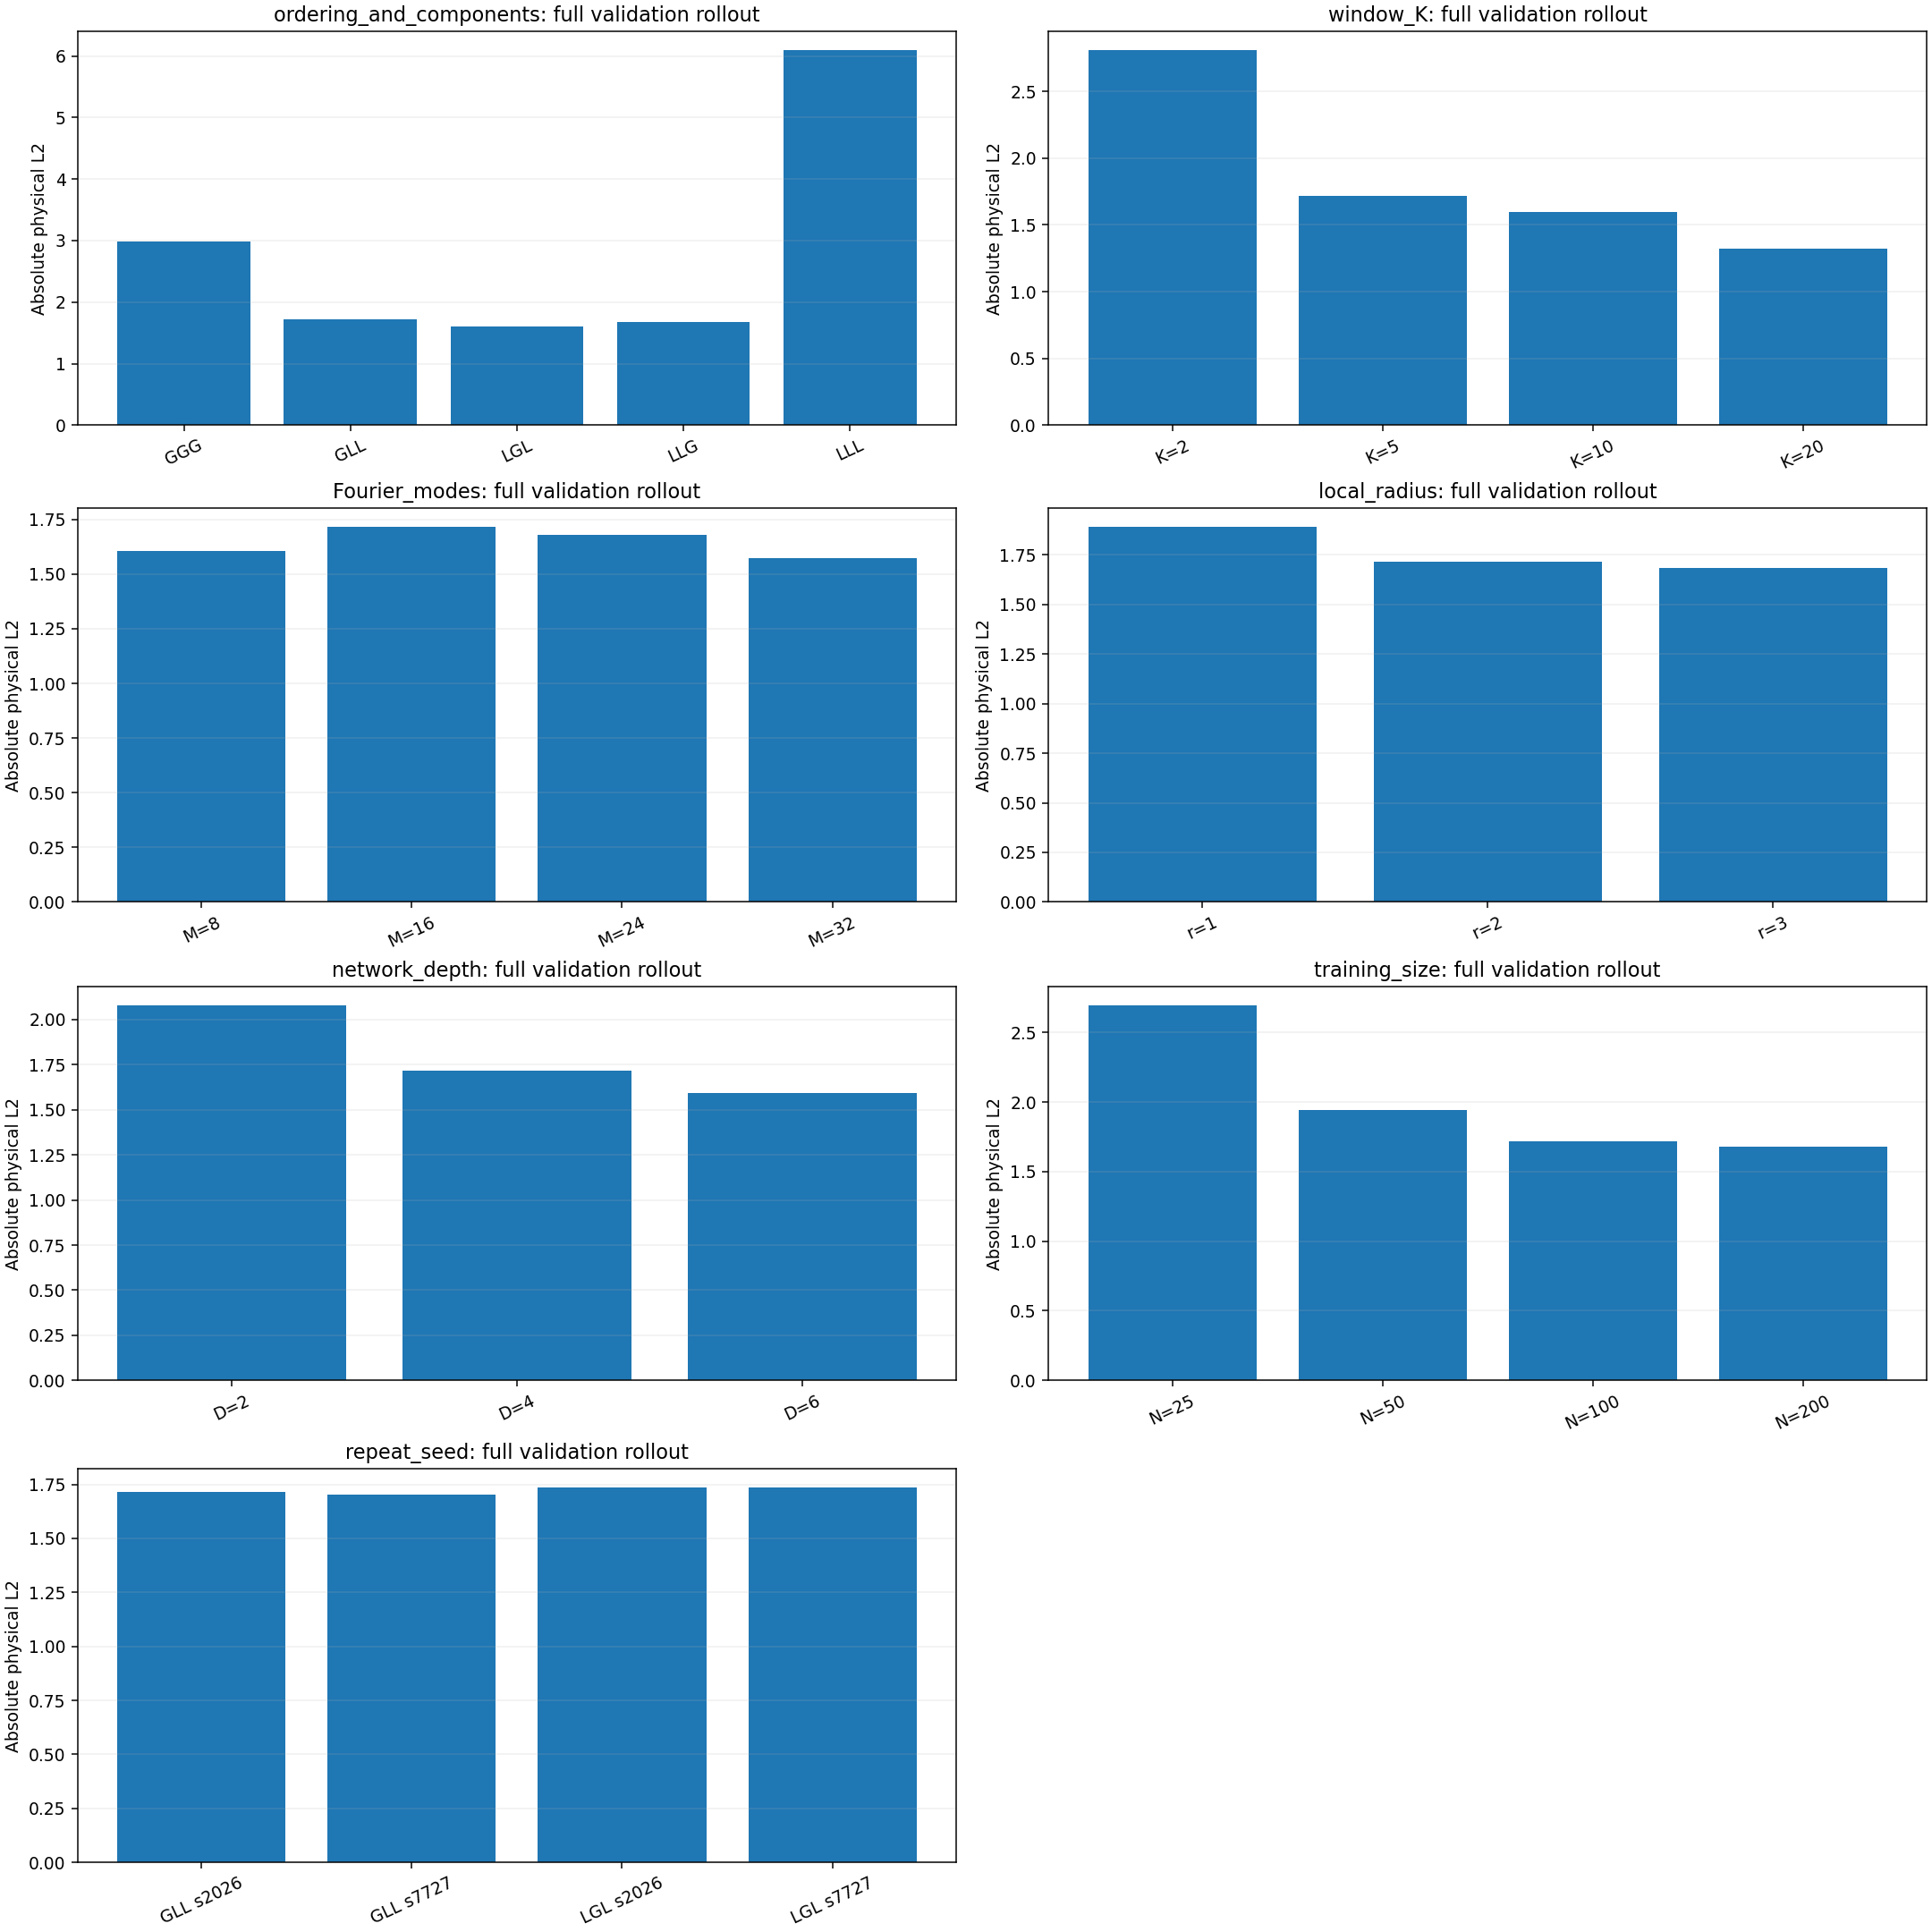

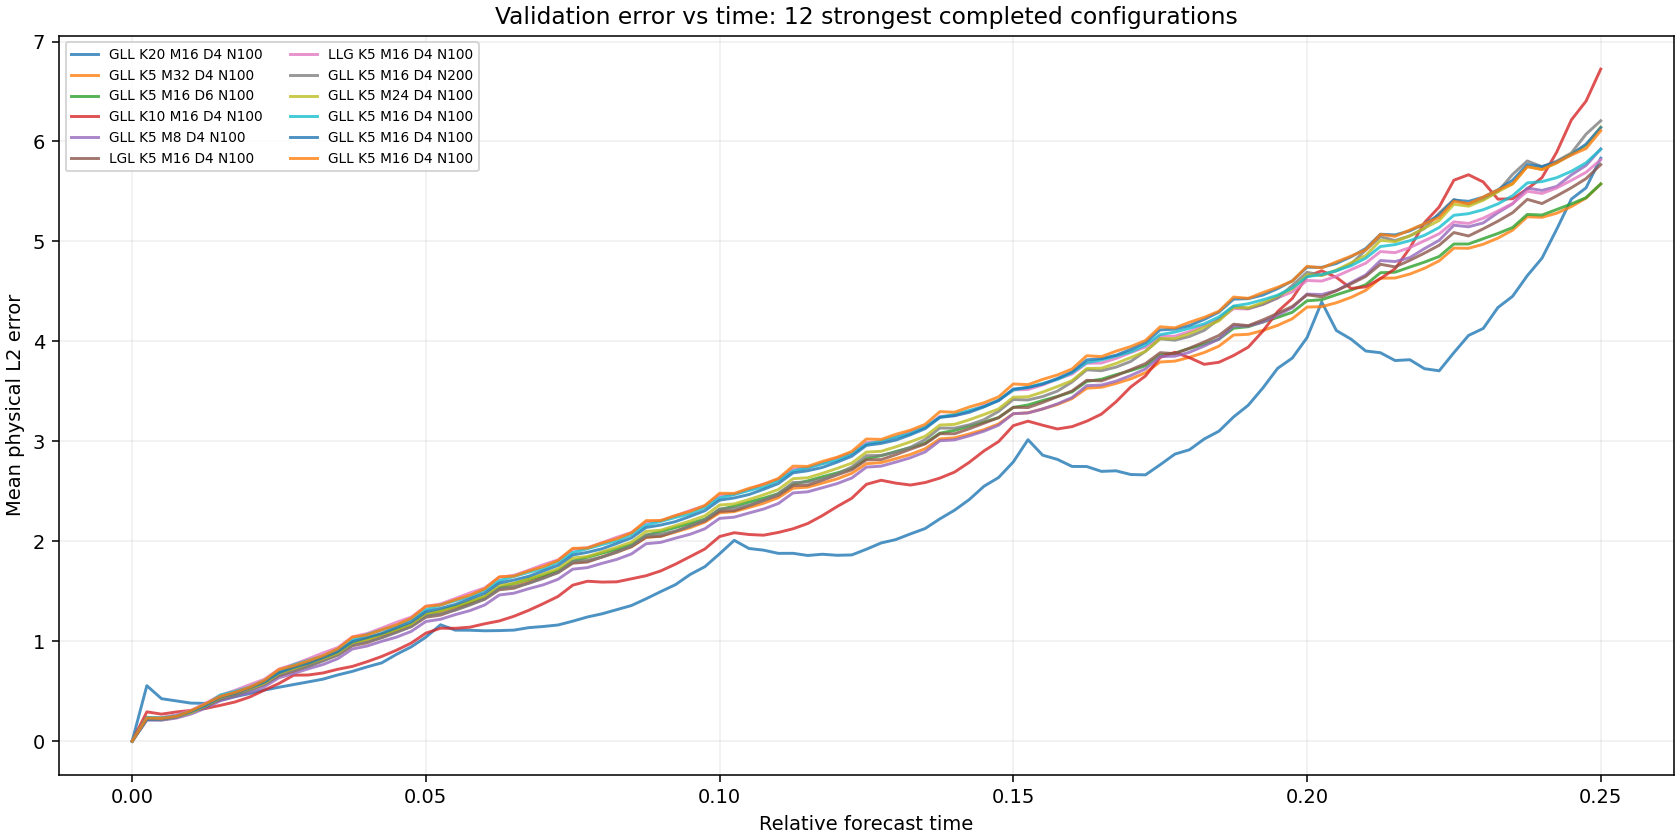

Best completed validation model: /content/drive/MyDrive/AWFNO_NS_Re500_101_FULL_ABLATIONS_v1/GLL_K20_N100_s1234_8506e9ac6f1e


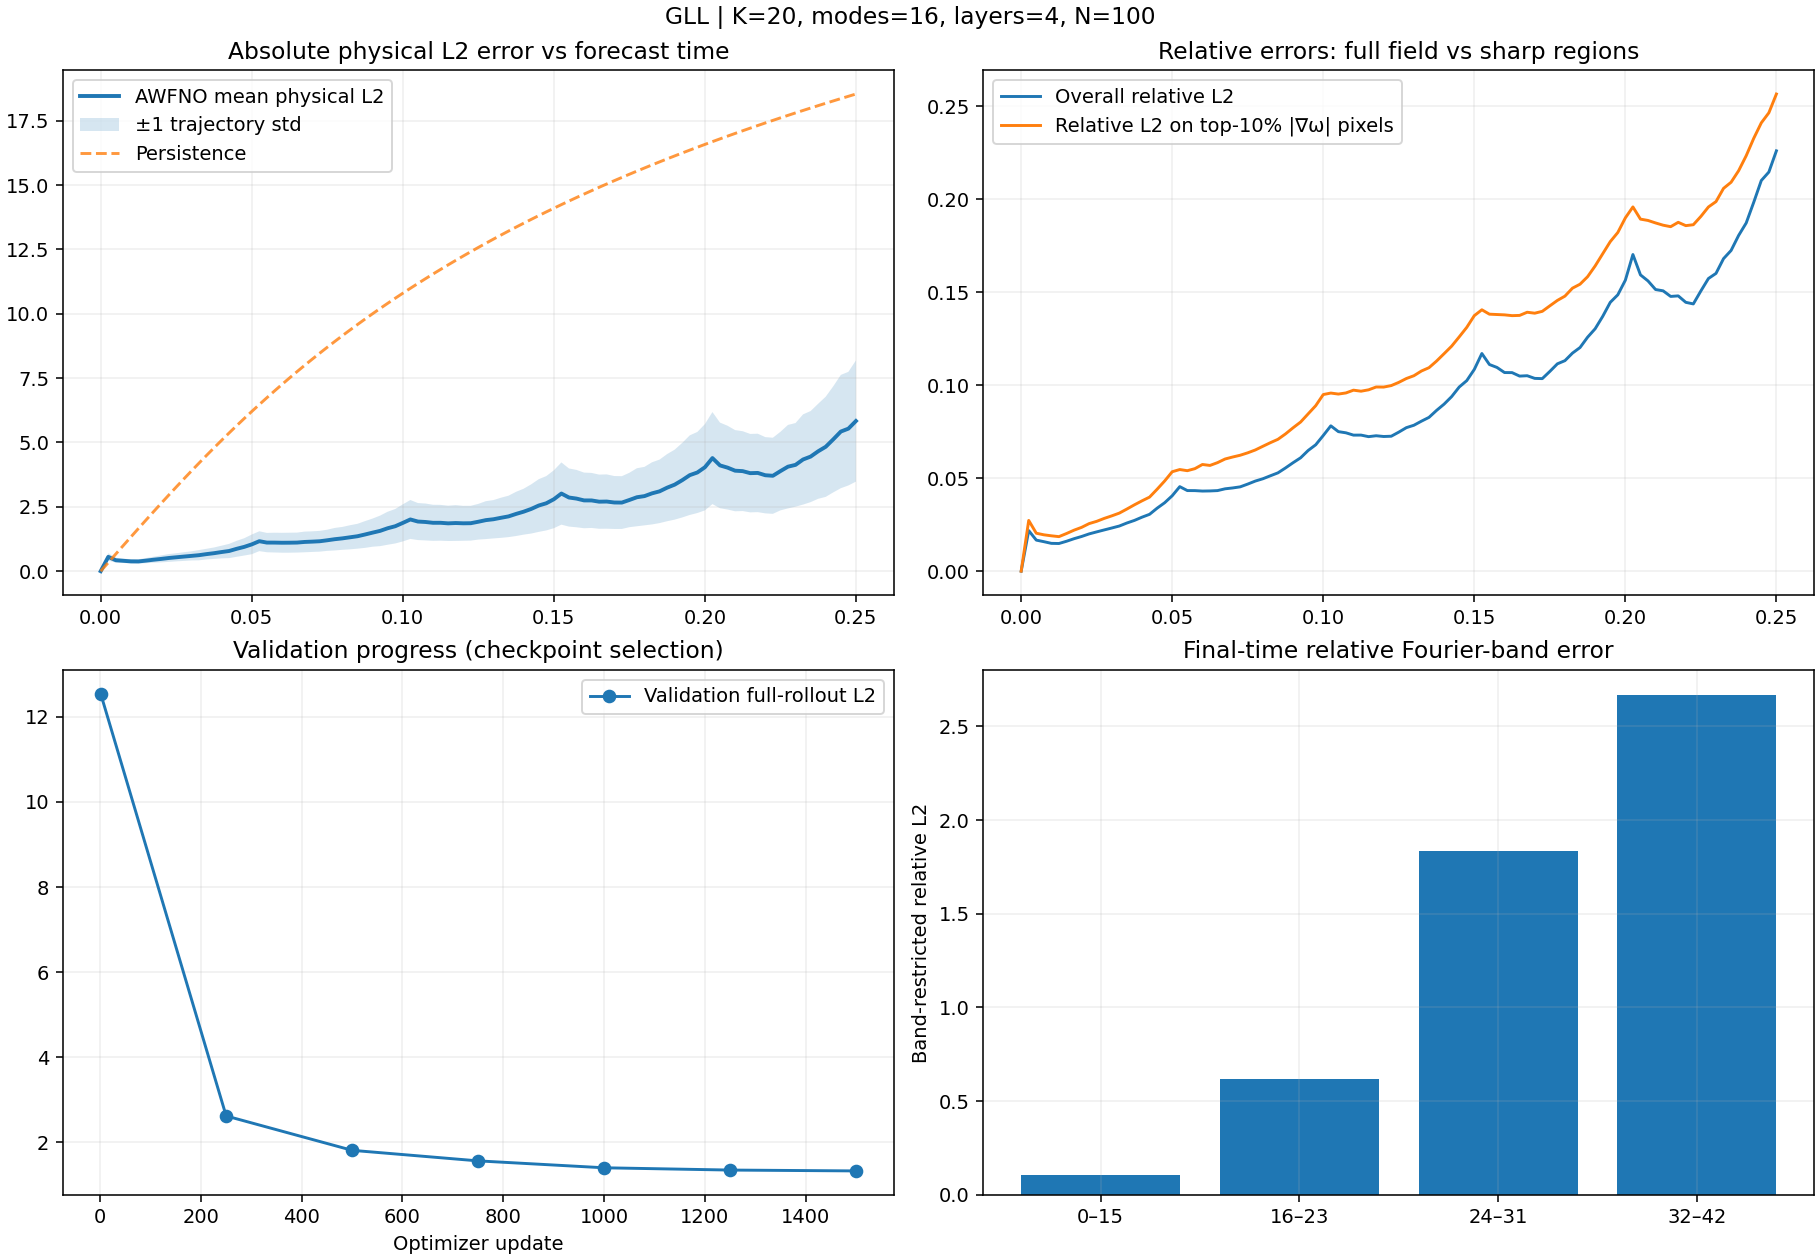

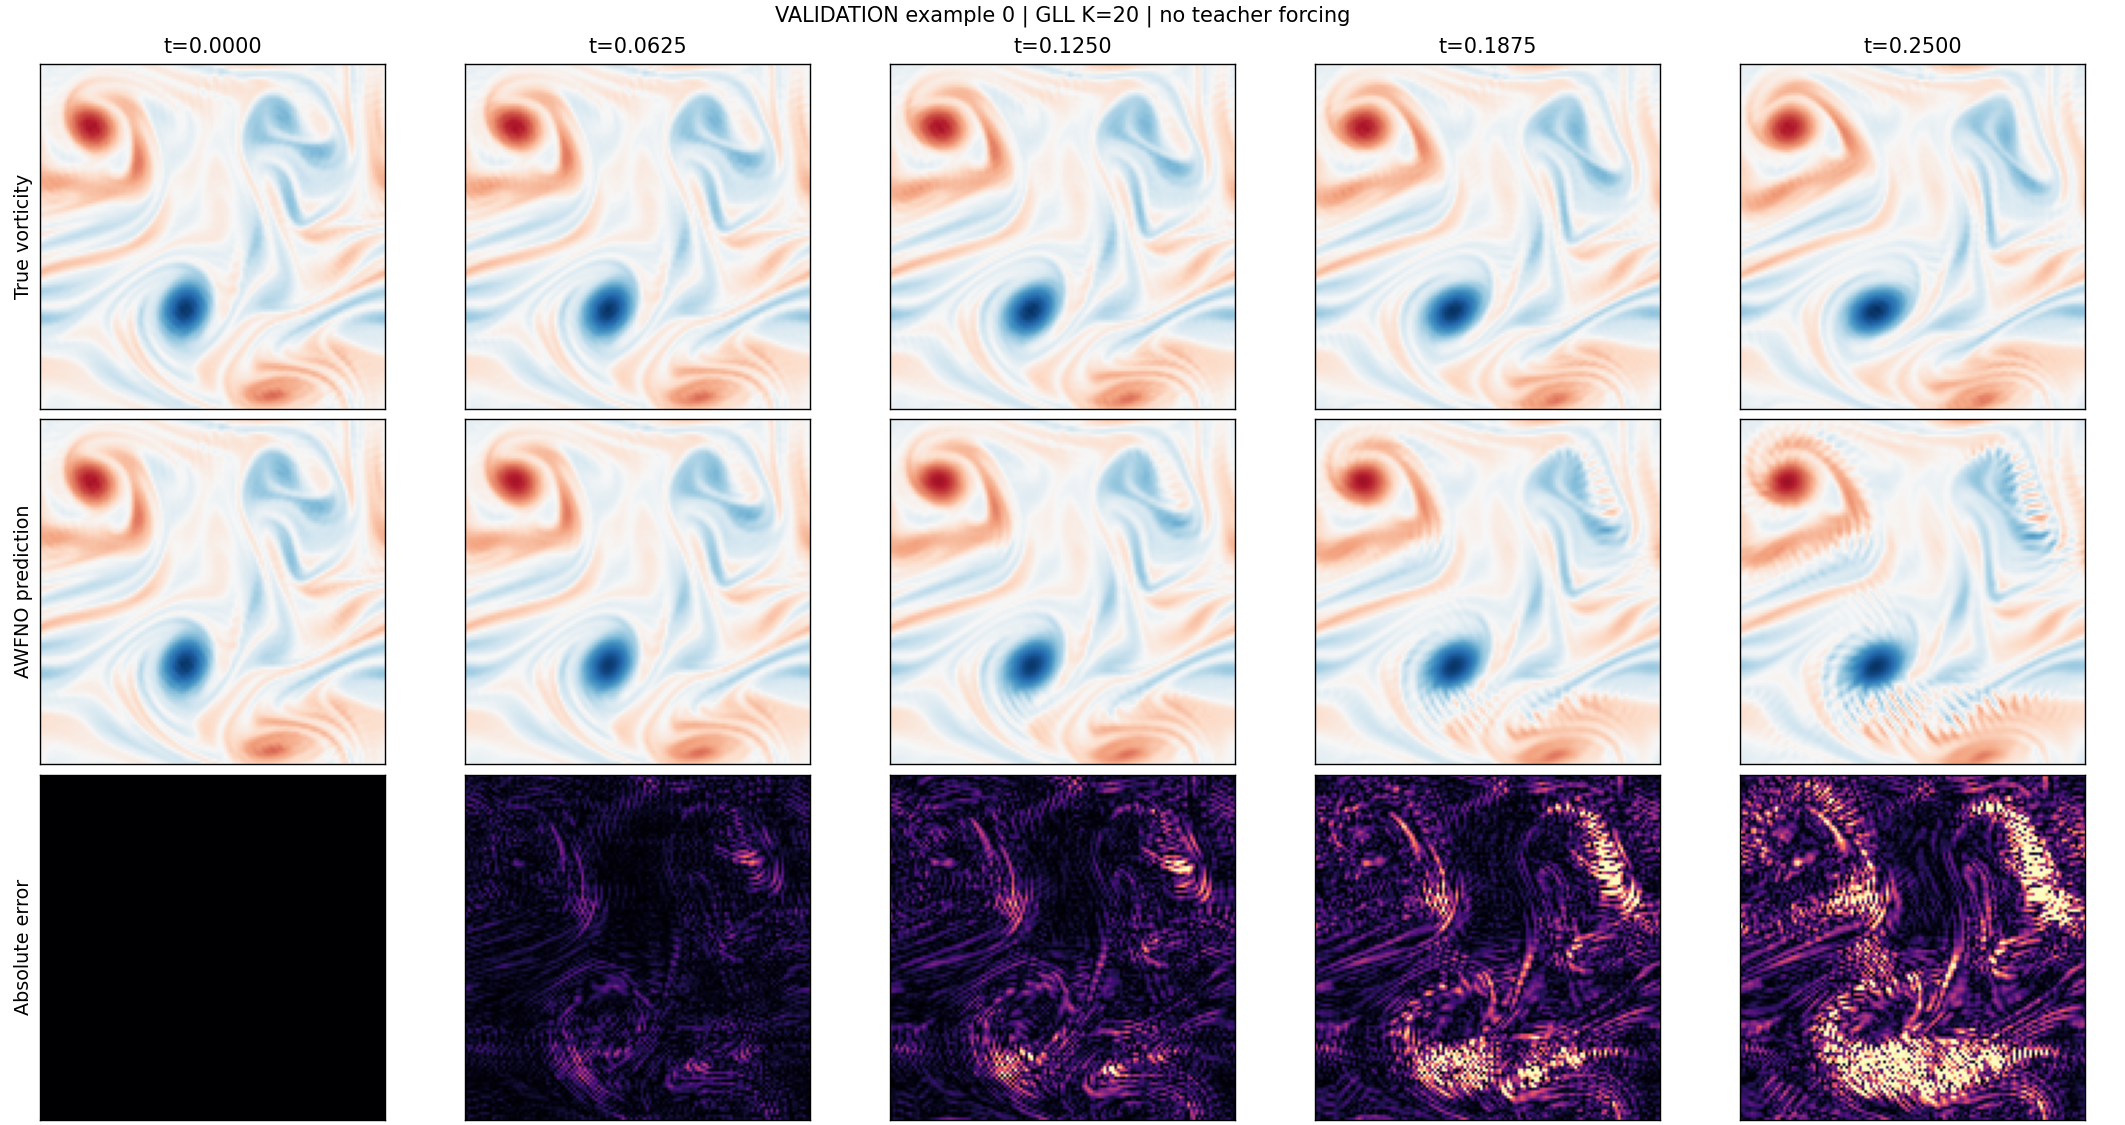

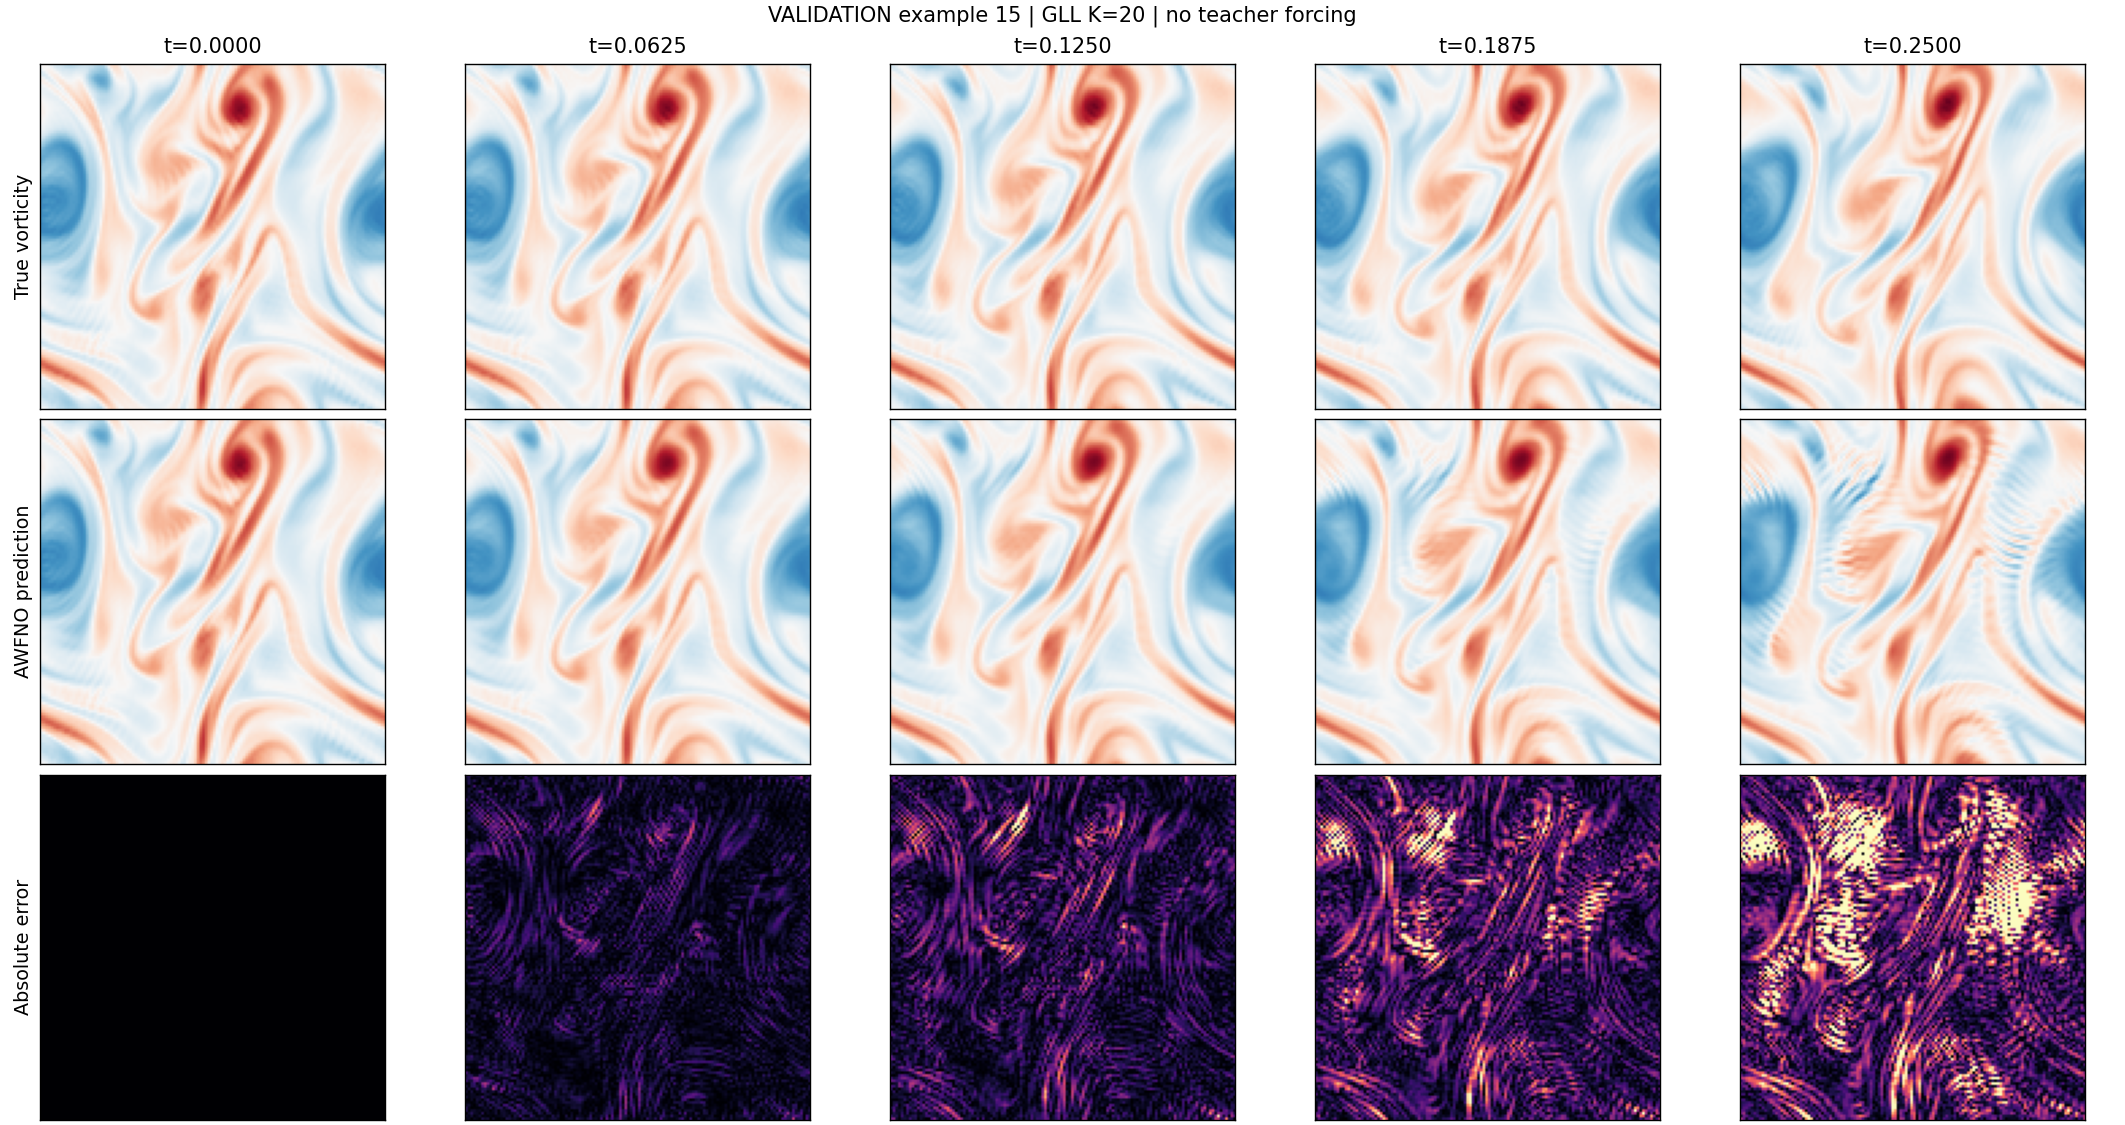

Test set remains SEALED; no test metrics are reported.


In [6]:
#@title 6. Display full ablation results and figures (all validation only)
from IPython.display import display,Image
import pandas as pd,json
table=ROOT/'ablation_results.csv'
if not table.is_file():
    print('No completed model results yet. Run Cell 5.')
else:
    df=pd.read_csv(table).sort_values('best_val_full_l2')
    display(df[['families','order','K','modes','radius','layers',
                'N_train','seed','parameters','best_val_full_l2',
                'best_val_final_l2','best_step','training_seconds']])
    print(f'Completed: {len(df)}/22 unique configurations')
    progress=ROOT/'suite_progress.json'
    if progress.exists():print('Progress:',json.loads(progress.read_text()))
    for name in ['ALL_ablation_comparison.png','ALL_error_vs_time.png']:
        pic=ROOT/name
        if pic.is_file():display(Image(filename=str(pic),width=1050))
    best=df.iloc[0]
    run_dir=ROOT/(
       f"{best['order']}_K{int(best['K'])}_N{int(best['N_train'])}_"
       f"s{int(best['seed'])}_{best['configuration_hash']}")
    print('Best completed validation model:',run_dir)
    for name in ['validation_diagnostics.png','validation_snapshots_example_0.png',
                 'validation_snapshots_example_15.png']:
        pic=run_dir/name
        if pic.is_file():display(Image(filename=str(pic),width=1100))
    print('Test set remains SEALED; no test metrics are reported.')
